# Carga dos Dados

In [ ]:
# Importação das bibliotecas
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [30]:
caminho_pasta = kagglehub.dataset_download("yashdev01/spotify-tracks-dataset")
print("Os arquivos foram baixados em:", caminho_pasta)
try:
  df = pd.read_csv(os.path.join(caminho_pasta, "spotify-tracks-dataset.csv"))
except FileNotFoundError:
  print("Erro ao carregar o arquivo CSV")
else:
  print("Importação concluída")

Os arquivos foram baixados em: C:\Users\beatr\.cache\kagglehub\datasets\yashdev01\spotify-tracks-dataset\versions\1
Importação concluída


# Descrição da Base e Pré-processamento dos Dados

A tabela abaixo apresenta o dicionário completo das variáveis analisadas após a supressão dos campos identificadores ou descritivos de texto livre. Conforme as boas práticas de análise multivariada, variáveis categóricas originalmente codificadas com números ou booleanos foram recodificadas com os nomes explícitos de suas categorias, e variáveis contínuas com forte assimetria receberam transformações de escala apropriadas:

| Abreviação / Nome no Modelo | Nome Original | Breve Descrição da Variável | Tipo da Variável |
| :--- | :--- | :--- | :--- |
| `popularity` | `popularity` | Índice de popularidade da faixa no Spotify baseado no volume e recência de reproduções (1 a 100). | Inteira (tratada como **Contínua** na regressão) |
| `danceability` | `danceability` | Adequação da faixa para dança com base em estabilidade rítmica, andamento e regularidade dos tempos (0,0 a 1,0). | Contínua |
| `energy` | `energy` | Medida perceptual de intensidade e atividade energética da faixa (0,0 a 1,0). | Contínua |
| `loudness_bc` | `loudness` | Volume médio geral da faixa em decibéis (dB), tipicamente entre $-50$ e $+5$ dB. | Contínua |
| `speechiness_t` | `speechiness` | Detecta a presença de palavras faladas na gravação (0,0 a 1,0). | Contínua |
| `acousticness` | `acousticness` | Grau de confiança de que a faixa é acústica (0,0 a 1,0). | Contínua |
| `instrumental` | `instrumentalness` | Grau de ausência de vocais na faixa (originalmente contínua de 0,0 a 1,0, fortemente bimodal). | **Categórica não ordinal** (binarizada) |
| `liveness_t` | `liveness` | Detecta a presença de público/audiência ao vivo na gravação (0,0 a 1,0). | Contínua |
| `valence` | `valence` | Positividade musical transmitida pela faixa (0,0 = triste/sombria a 1,0 = alegre/eufórica). | Contínua |
| `tempo` | `tempo` | Andamento estimado da faixa em batidas por minuto (BPM). | Contínua |
| `duration_log` | `duration_ms` | Duração total da faixa musical. | Contínua |
| `nota` | `key` | Tonalidade principal da música no padrão *Pitch Class* (12 notas cromáticas). | Categórica não ordinal |
| `modo` | `mode` | Modalidade da escala musical da faixa. | Categórica não ordinal |
| `explicita` | `explicit` | Indica se a letra da música contém linguagem explícita. | Categórica não ordinal |
| `compasso` | `time_signature` | Fórmula de compasso estimada (número de batidas por compasso). | Categórica não ordinal |
| `track_genre` | `track_genre` | Gênero musical associado à faixa no catálogo (114 categorias). | Categórica não ordinal |

## Limpeza Inicial

Nesta primeira etapa de pré-processamento, a estrutura da base foi inspecionada, na medida em que a existência de valores ausentes e registros duplicados foi verificada, anomalias de catalogação e variáveis puramente identificadoras ou textuais que não devem compor modelos de regressão também foram manejadas.

In [31]:
print(df.shape)
df.info()

print(f'\nMissing values:\n{df.isnull().sum()[df.isnull().sum() > 0]}')
print(f'\nDuplicate values:\n{df.duplicated().sum()}')

df.drop(columns=[c for c in df.columns if 'Unnamed' in c], inplace=True)

print(f'\nDuplicate values after cleaning:\n{df.duplicated().sum()}')

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'\nShape sem duplicatas exatas: {df.shape}')
print(f'track_id repetidos em mais de um gênero: {df.duplicated(subset="track_id").sum()}')

# remoção de músicas com duração inválida
print(f'\nmúsicas com duração <= 0: {(df["duration_ms"] <= 0).sum()}')
df = df[df['duration_ms'] > 0].reset_index(drop=True)

# remoção de músicas com compasso 0/4 (inexistente musicalmente)
print(f'músicas com compasso 0/4: {(df["time_signature"] == 0).sum()}')
df = df[df['time_signature'] != 0].reset_index(drop=True)

df_genero = df[['track_genre', 'popularity']].copy()

# desduplicação por 'track_id' para garantir que cada música seja uma observação única e independente na regressão
df.drop_duplicates(subset='track_id', inplace=True)

# supressão dos campos id
df.drop(columns=['track_id', 'artists', 'album_name', 'track_name', 'track_genre'], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Shape final: {df.shape}')

(114000, 22)
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  str    
 3   artists           113999 non-null  str    
 4   album_name        113999 non-null  str    
 5   track_name        113999 non-null  str    
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  

In [32]:
# lista com a nomenclatura musical padrão, pitch class, para mapear os códigos numéricos de 0 a 11 da variável key
key_names = ['C', 'C♯/D♭', 'D', 'D♯/E♭', 'E', 'F', 'F♯/G♭', 'G', 'G♯/A♭', 'A', 'A♯/B♭', 'B']

# conversão da duração de ms para min
df['duration_min'] = df['duration_ms'] / 60000

# substituição dos códigos numéricos/booleanos pelos descritivos das categorias
df['nota'] = df['key'].map(lambda x: key_names[x] if 0 <= x <= 11 else 'Desconhecida')
df['modo'] = df['mode'].map({0: 'Menor', 1: 'Maior'})
df['explicita'] = df['explicit'].map({False: 'Não explícita', True: 'Explícita'})
df['compasso'] = df['time_signature'].map(lambda x: f'{x}/4')

# lista com as 10 características técnicas numéricas para análise exploratória
caract_tec = [
    'danceability','energy','loudness','speechiness','acousticness',
    'instrumentalness','liveness','valence','tempo','duration_min'
]

print("Colunas recodificadas criadas com sucesso:", ['duration_min', 'nota', 'modo', 'explicita', 'compasso'])
print("Variáveis categóricas mapeadas:")
print(df[['nota', 'modo', 'explicita', 'compasso', 'duration_min']].head(5).round(2))

Colunas recodificadas criadas com sucesso: ['duration_min', 'nota', 'modo', 'explicita', 'compasso']
Variáveis categóricas mapeadas:
    nota   modo      explicita compasso  duration_min
0  C♯/D♭  Menor  Não explícita      4/4          3.84
1  C♯/D♭  Maior  Não explícita      4/4          2.49
2      C  Maior  Não explícita      4/4          3.51
3      C  Maior  Não explícita      3/4          3.37
4      D  Maior  Não explícita      4/4          3.31


In [33]:
df.drop(columns=['duration_ms', 'key', 'mode', 'explicit', 'time_signature'], inplace=True)
print(f"\nShape após substituição pelas colunas recodificadas: {df.shape}")


Shape após substituição pelas colunas recodificadas: (89578, 15)


**Discussão da limpeza inicial e tratamento estrutural:**

- **Índices e duplicatas exatas:** Foram retiradas as duas colunas de índice, o que revelou as linhas duplicadas e, agora, eliminadas. O único registro com valor ausente nas colunas `artists`, `album_name` e `track_name` correspondia justamente à música com duração de `0 ms`. De qualquer forma, essas colunas textuais descritivas são suprimidas na modelagem.
- **Anomalias na extração de áudio:** Foi removida 1 música com `duration_ms <= 0` e 163 músicas com compasso `0/4` (`time_signature == 0`), valor que não existe na teoria musical e é consequência de falha do algoritmo de detecção rítmica do Spotify. Cabe destacar que todas as 157 músicas que apresentavam `tempo == 0` BPM na base bruta estavam contidas dentro dessas 163 músicas com compasso `0/4`. Desse modo, a remoção de `time_signature == 0` eliminou automaticamente todo os registros com andamento nulo (`tempo == 0`), passando o valor mínimo de `tempo` a ser 30,32 BPM.
- **Independência das observações e `track_id` repetidos:** Identificamos 23.809 repetições de `track_id`, pois uma mesma gravação pode ser classificada simultaneamente em múltiplos gêneros musicais. Manter a mesma música repetida várias vezes na matriz de regressão afetaria frontalmente a premissa de independência dos erros, além de inflar artificialmente os graus de liberdade. Por essa razão, mantivemos no DataFrame principal (`df`) apenas uma observação única por `track_id`. Como o gênero atribuído à primeira aparição seria arbitrário, a coluna `track_genre` foi separada no DataFrame auxiliar `df_genero`, para análise exploratória, e removida de `df` juntamente com os campos identificadores (`track_id`, `artists`, `album_name` e `track_name`).
- **Recodificação categórica e ajuste de unidade:** Por fim, convertemos `duration_ms` para minutos (`duration_min`) e substituímos os códigos numéricos/booleanos de `key`, `mode`, `explicit` e `time_signature` por seus respectivos nomes categóricos (`nota`, `modo`, `explicita` e `compasso`).

## Inspeção e Tratamento da Variável Resposta (`popularity`)

Antes de analisar as variáveis preditoras, inspecionamos o comportamento da variável resposta `popularity` para verificar sua distribuição empírica, medidas de tendência central, assimetria e eventuais distorções nos extremos da escala.

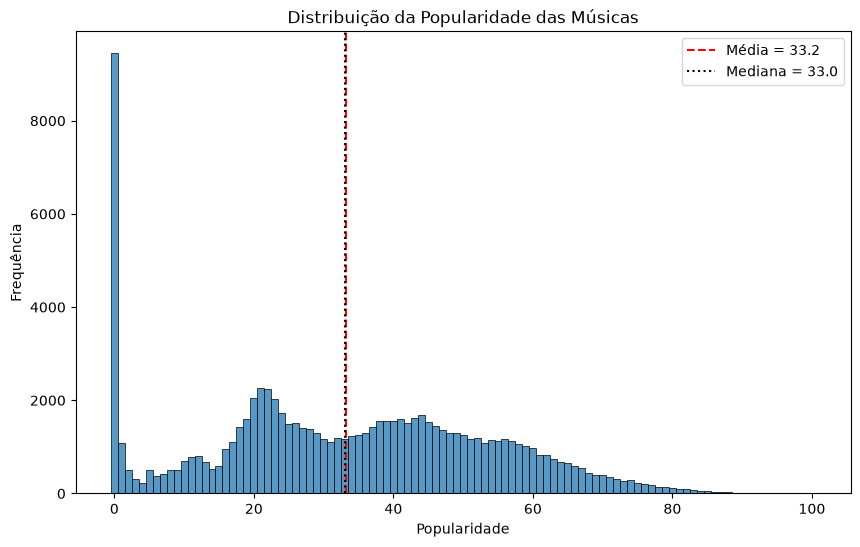

count    89578.000000
mean        33.192056
std         20.593237
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

Assimetria: 0.071
Popularidade igual a 0: 9443 (10.54%)


In [34]:
# plotagem do histograma da variável resposta popularity incluindo os registros iguais a zero
plt.figure(figsize=(10, 6))
sns.histplot(df['popularity'], discrete=True)

# adição de linhas indicando a média e a mediana
plt.axvline(df['popularity'].mean(), color="red", linestyle="--", label=f'Média = {df["popularity"].mean():.1f}')
plt.axvline(df['popularity'].median(), color="black", linestyle=":", label=f'Mediana = {df["popularity"].median():.1f}')
plt.legend()

plt.title('Distribuição da Popularidade das Músicas')
plt.xlabel('Popularidade')
plt.ylabel('Frequência')
plt.show()

# estatísticas descritivas, coeficiente de assimetria (skewness) e proporção de zeros
print(df['popularity'].describe())
print(f'\nAssimetria: {df["popularity"].skew():.3f}')
print(f'Popularidade igual a 0: {(df["popularity"] == 0).sum()} ({(df["popularity"] == 0).mean() * 100:.2f}%)')

Observa-se no gráfico acima uma forte inflação de zeros. Há 9.443 músicas com `popularity == 0`. A seguir, está a distribuição da popularidade restringindo a amostra às músicas ativas (`popularity > 0`) e a filtragem correspondente.

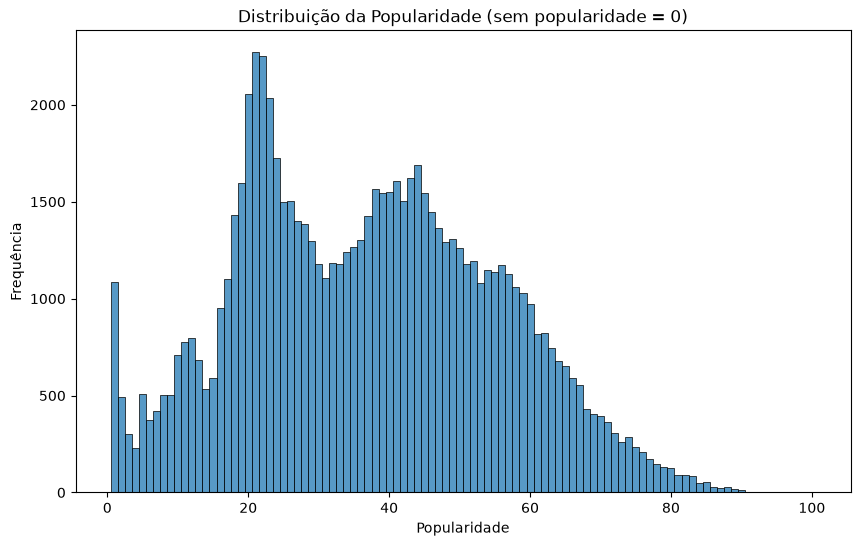

In [35]:
# visualização do histograma da popularidade excluindo o pico em zero
plt.figure(figsize=(10, 6))
sns.histplot(df[df['popularity'] > 0]['popularity'], discrete=True)

plt.title('Distribuição da Popularidade (sem popularidade = 0)')
plt.xlabel('Popularidade')
plt.ylabel('Frequência')
plt.show()

In [36]:
# remoção dos registros com popularidade igual a zero
print(f'músicas com popularidade = 0 removidas: {(df["popularity"] == 0).sum()}')

# aplicação do filtro tanto na base principal de modelagem (df) quanto na base auxiliar de gêneros (df_genero)
df = df[df['popularity'] > 0].reset_index(drop=True)
df_genero = df_genero[df_genero['popularity'] > 0].reset_index(drop=True)

# exibição do novo tamanho amostral (n = 80.135) e das estatísticas descritivas atualizadas
print(f'Shape após remover popularidade = 0: {df.shape}')
print(df['popularity'].describe())

músicas com popularidade = 0 removidas: 9443
Shape após remover popularidade = 0: (80135, 15)
count    80135.000000
mean        37.103363
std         18.136449
min          1.000000
25%         22.000000
50%         37.000000
75%         50.000000
max        100.000000
Name: popularity, dtype: float64


**Justificativa estatística para a remoção de `popularity == 0`:**

O índice de popularidade do Spotify é calculado algoritmicamente a partir do volume total e da recência das reproduções, isto é, os streams. Por esse motivo, o valor `0` atua como um piso censurado que agrupa situações heterogêneas e não musicais, ou seja, lançamentos muito recentes ainda não indexados pelo algoritmo, revisões/repetições de catálogo, músicas antigas sem reproduções recentes ou músicas utilitárias. Nesses casos, o zero representa ausência de informação de engajamento recente, que é um comportamento análogo a dado faltante ou não informado, e a sua permanência criaria uma massa pontual artificial na cauda esquerda da distribuição e nos resíduos da regressão.

Após a remoção dessas músicas, a base final de modelagem passa a contar com $n = 80.135$ músicas únicas ativas, com média de 37,11, mediana de 37, desvio-padrão de 18,13 e assimetria muito baixa ($\text{skewness} = 0,182$). Ademais, a transformação Box-Cox sobre `popularity` ($\lambda \approx 0,757$) foi testada, mas a assimetria apenas mudou de $+0,182$ para $-0,123$, sem eliminar o caráter bimodal da curva, que possui modas locais próximas de 20 e de 40. Assim, optamos por manter `popularity` em sua escala original (1 a 100), preservando a interpretação direta dos coeficientes em pontos de popularidade. Como limitação explícita, as inferências do modelo aplicam-se ao universo de músicas ativas (`popularity > 0`).

## Gêneros Musicais

A seguir, analisamos no df auxiliar `df_genero` a distribuição de frequências dos 114 gêneros musicais após a limpeza e verificamos os gêneros com as maiores e menores médias de popularidade.


 Quantidade de gêneros musicais do dataset:
 114


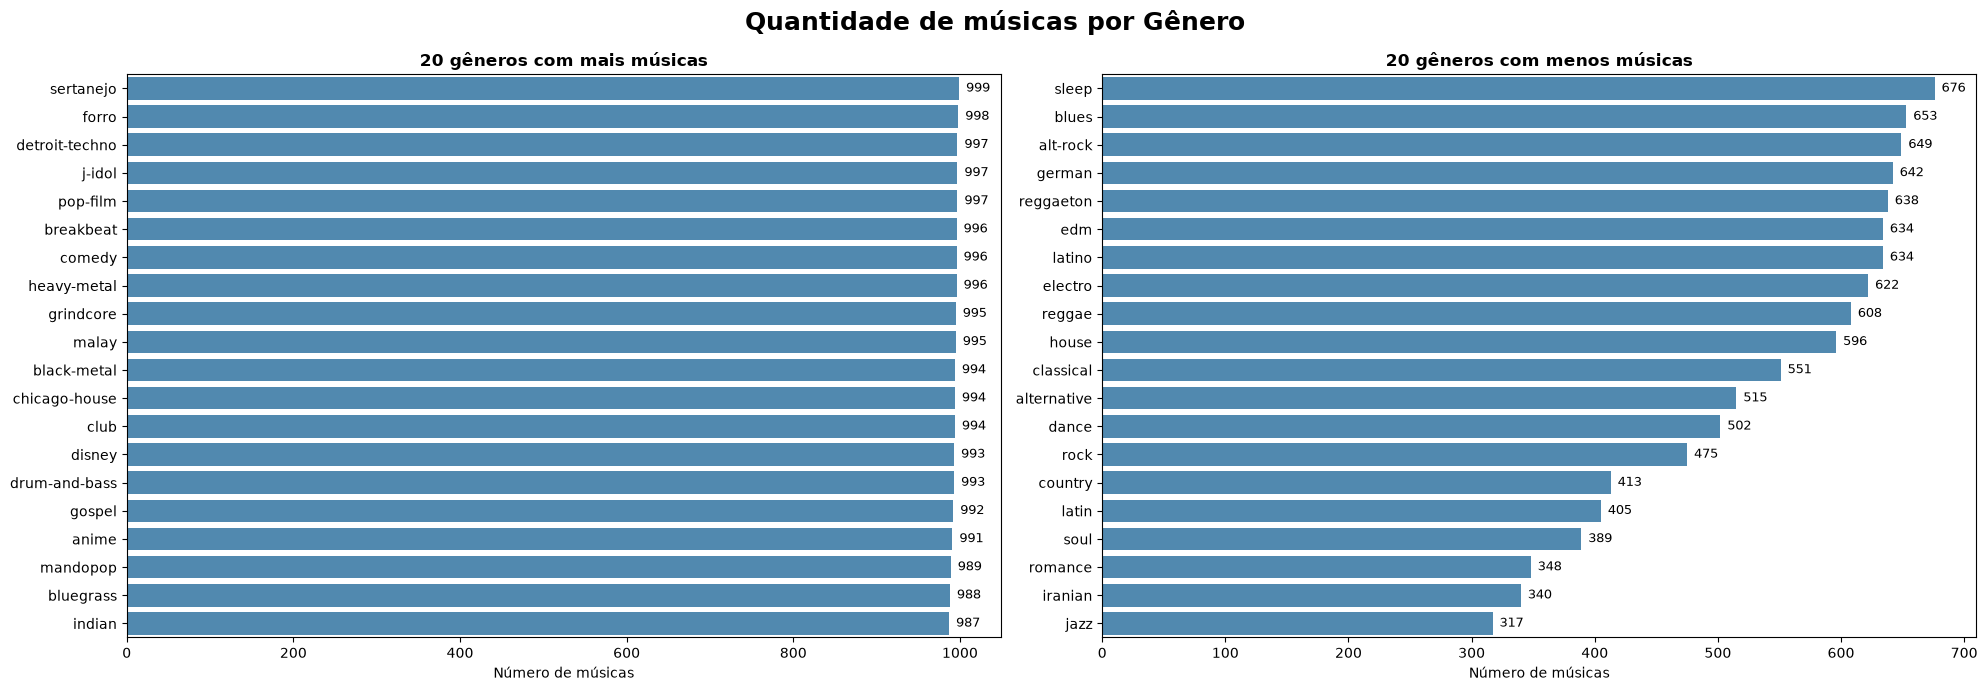

count    114.000000
mean     855.675439
std      173.778849
min      317.000000
25%      790.750000
50%      930.000000
75%      981.000000
max      999.000000
Name: count, dtype: float64


In [37]:
print(f'\n Quantidade de gêneros musicais do dataset:\n {df_genero["track_genre"].nunique()}')

contagem_genero = df_genero['track_genre'].value_counts()
# separação dos 20 gêneros mais frequentes e 20 menos frequentes
top_contagem = contagem_genero.head(20)
bottom_contagem = contagem_genero.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('Quantidade de músicas por Gênero', fontsize=18, fontweight='bold')

sns.barplot(ax=axes[0], x=top_contagem.values, y=top_contagem.index, alpha=0.85)
axes[0].set_title("20 gêneros com mais músicas", fontsize=12, fontweight='bold')

sns.barplot(ax=axes[1], x=bottom_contagem.values, y=bottom_contagem.index, alpha=0.85)
axes[1].set_title("20 gêneros com menos músicas", fontsize=12, fontweight='bold')

for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("Número de músicas")
    if ax.containers:
        ax.bar_label(ax.containers[0], padding=5, fontsize=9)

plt.tight_layout()
plt.show()

print(contagem_genero.describe())

Nota-se que, embora a base original contivesse exatamente 1.000 faixas por gênero, a remoção das faixas inativas (`popularity == 0`) afetou os gêneros de maneira desigual. Assim, gêneros como `forro`, `sertanejo`, `gospel` e `deep-house` mantiveram quase todas as faixas ativas, enquanto gêneros de nicho como `iranian`, `romance` e `detroit-techno` tiveram grande parte de seus registros filtrados por apresentarem popularidade zero. A seguir, comparamos a popularidade média entre os gêneros:

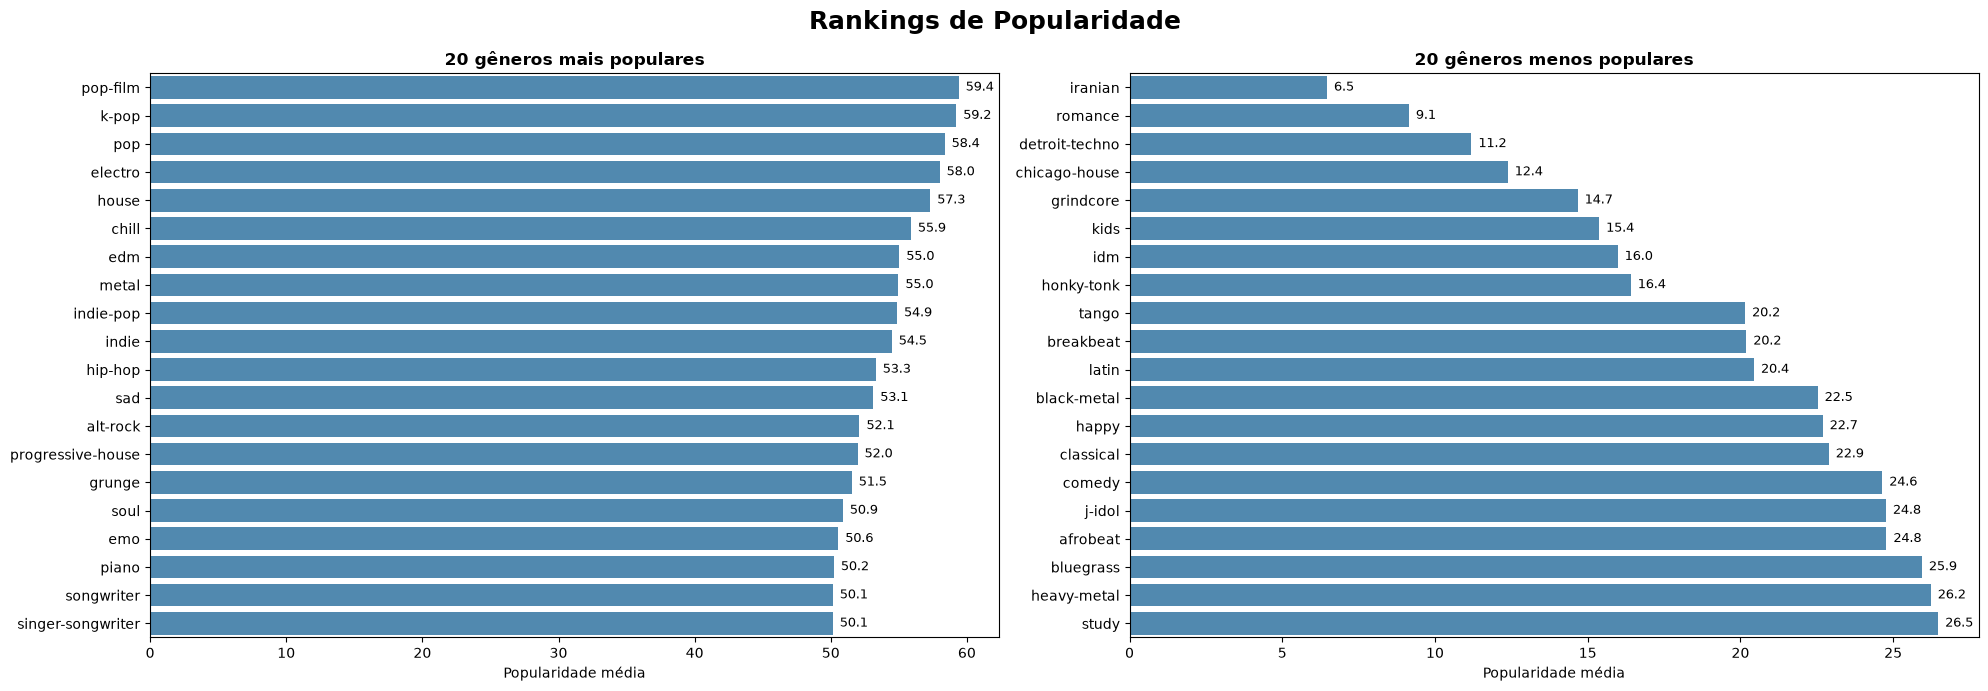

In [38]:
# cálculo da popularidade média por gênero musical
top_pop_genres = df_genero.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(20)
bottom_pop_genres = df_genero.groupby('track_genre')['popularity'].mean().sort_values().head(20)

# rankings de popularidade média por gênero
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('Rankings de Popularidade', fontsize=18, fontweight='bold')

sns.barplot(ax=axes[0], x=top_pop_genres.values, y=top_pop_genres.index, alpha=0.85)
axes[0].set_title("20 gêneros mais populares", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Popularidade média")

sns.barplot(ax=axes[1], x=bottom_pop_genres.values, y=bottom_pop_genres.index, alpha=0.85)
axes[1].set_title("20 gêneros menos populares", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Popularidade média")

for ax in axes:
    ax.set_ylabel("")
    if ax.containers:
        ax.bar_label(ax.containers[0], fmt='%.1f', padding=5, fontsize=9)

plt.tight_layout()
plt.show()

Os gráficos acima demonstram que a popularidade média varia substancialmente conforme o gênero musical. Apesar dessa associação empírica, a variável `track_genre` não foi incluída diretamente na equação de regressão por duas razões metodológicas fundamentais:
- **Alta cardinalidade:** Sua inclusão direta exigiria a criação de 113 variáveis indicadoras, reduzindo drasticamente a parcimônia e a interpretabilidade do modelo.
- **Multiplicidade de gêneros por faixa:** Na base original, uma mesma música (`track_id`) pertence simultaneamente a vários gêneros. Para garantir observações independentes, não é possível atribuir um único gênero verdadeiro sem cair em escolha arbitrária. Ademais, o nosso objetivo analítico central é investigar o poder explicativo das características acústicas e estruturais intrínsecas da música.

## Diagnóstico de Assimetria e Transformações de Escala nas Variáveis Numéricas

Variáveis numéricas com alta assimetria (*skewness*) exercem forte impacto negativo sobre a análise de regressão linear, distorcendo a estimativa por Mínimos Quadrados Ordinários (MQO) devido a valores extremos de leverage. Abaixo, inspecionamos os histogramas, *boxplots*, estatísticas descritivas e coeficientes de assimetria das 10 variáveis preditoras numéricas em sua escala original.

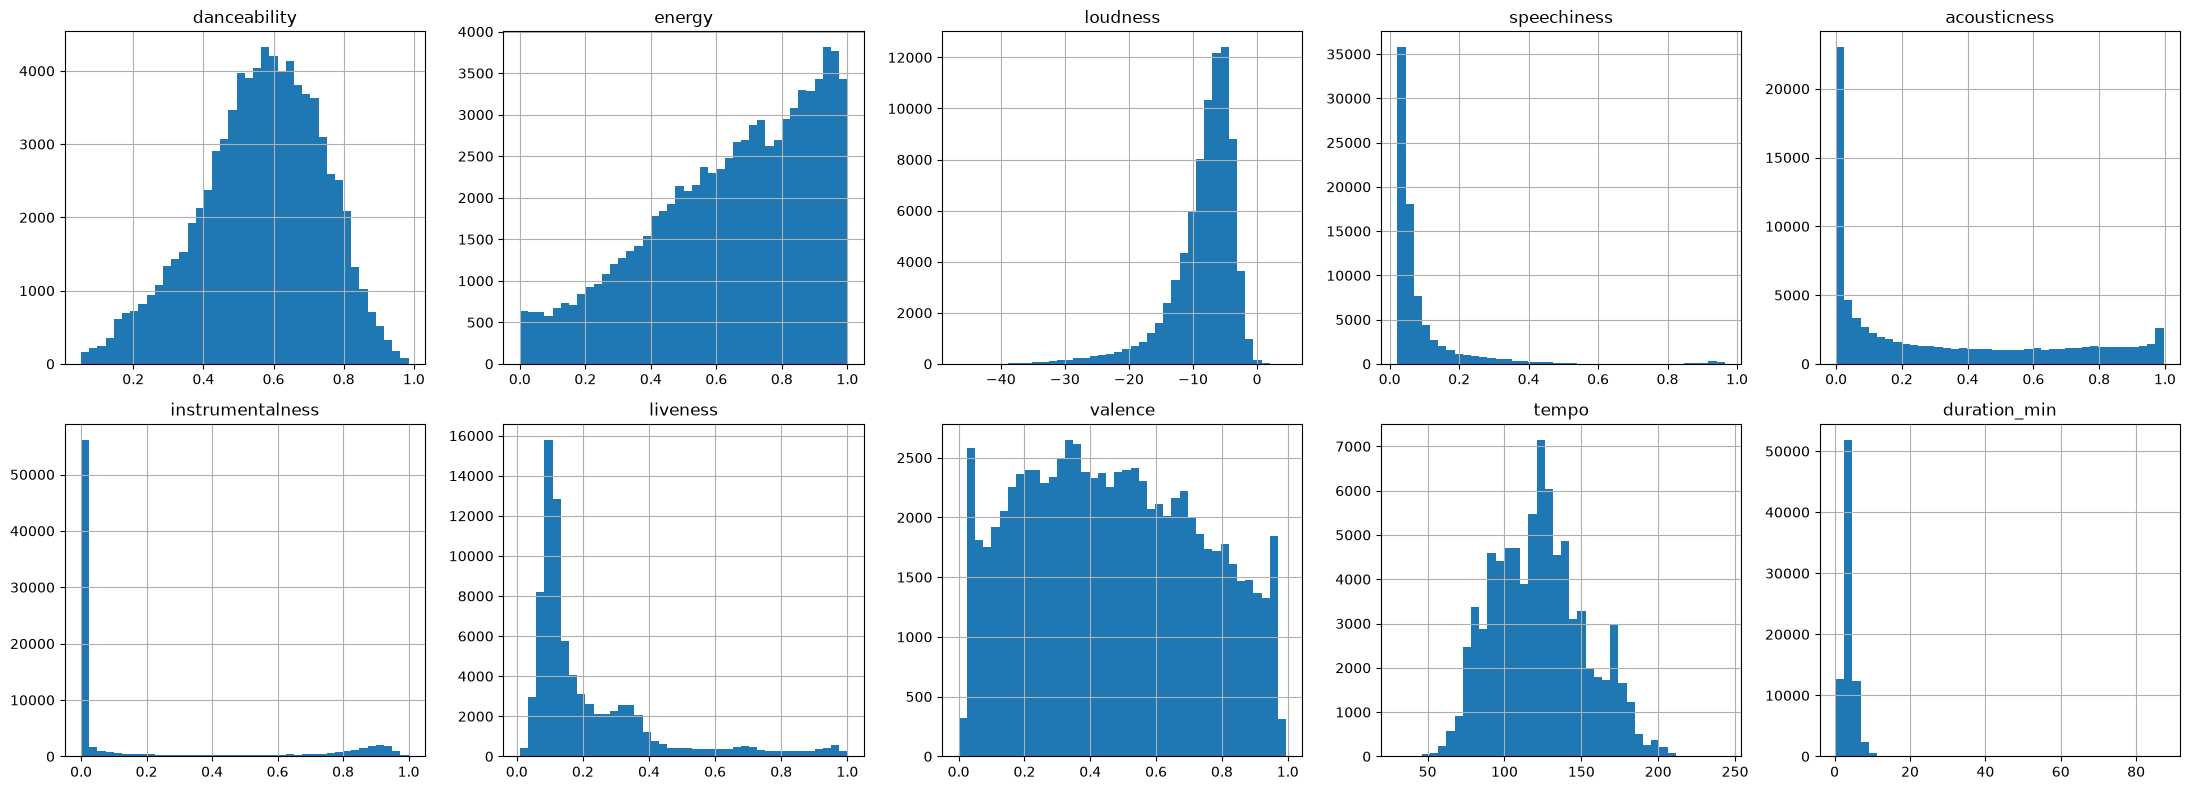

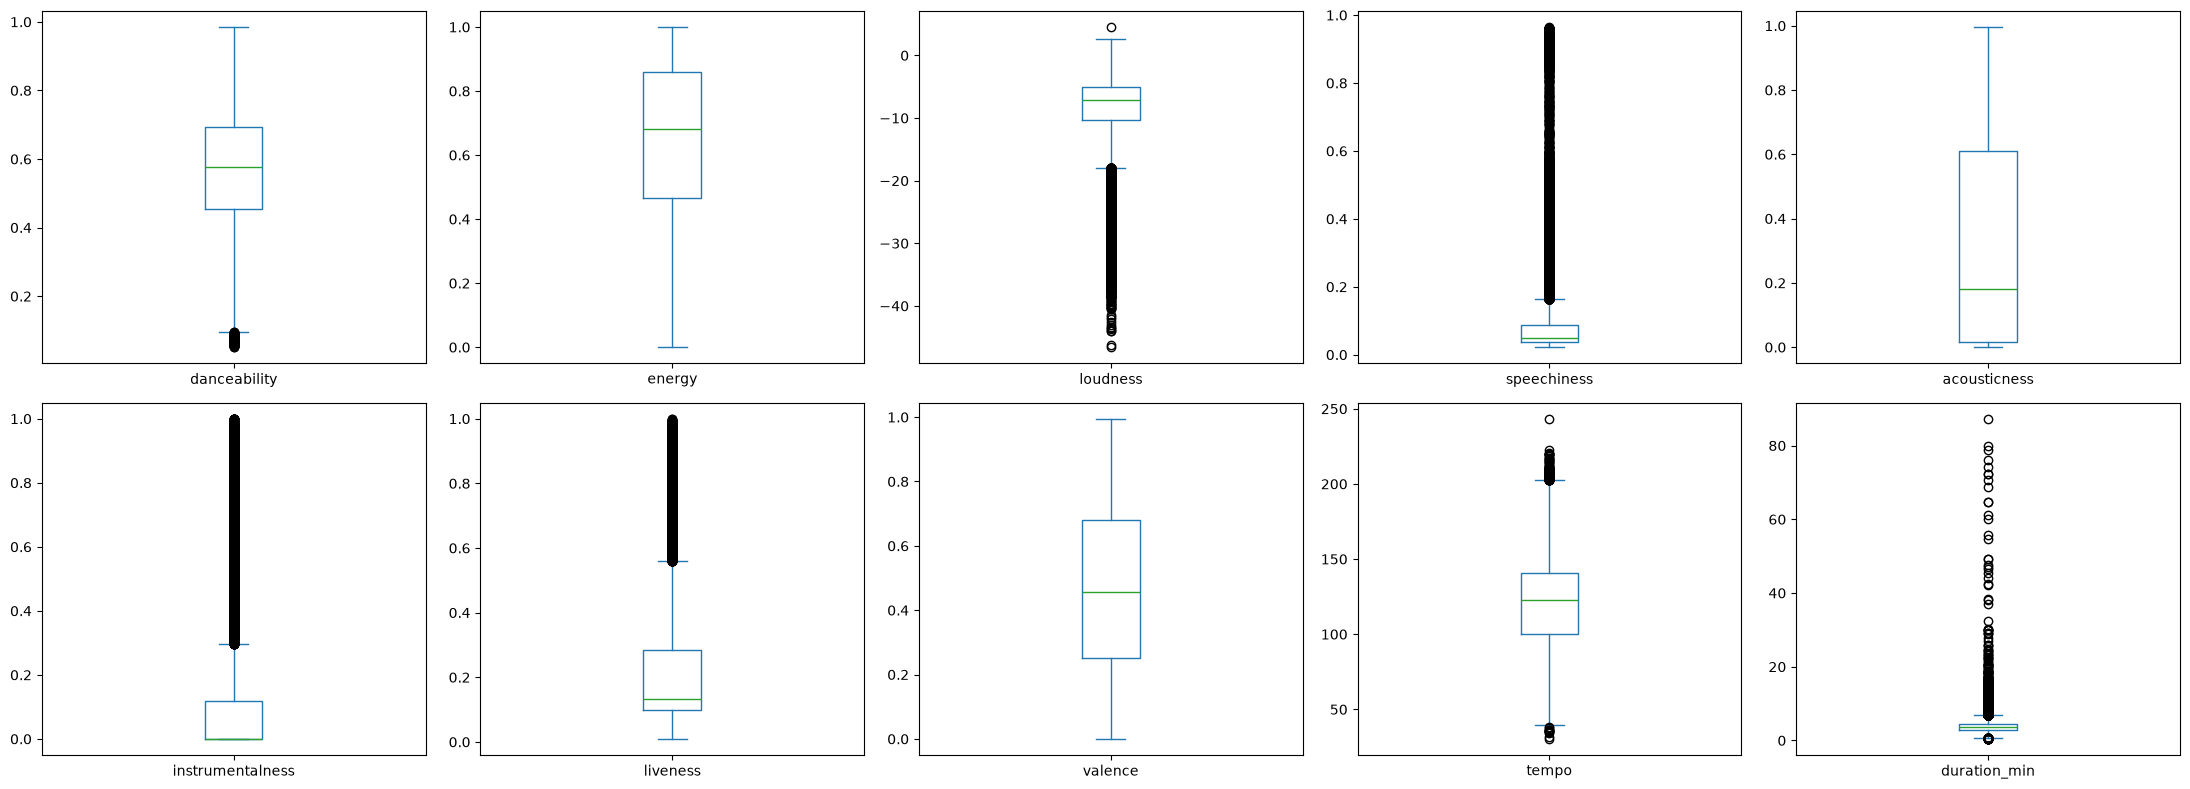

       danceability     energy   loudness  speechiness  acousticness  \
count     80135.000  80135.000  80135.000    80135.000     80135.000   
mean          0.564      0.642     -8.425        0.089         0.321   
std           0.174      0.253      5.104        0.117         0.334   
min           0.051      0.000    -46.591        0.022         0.000   
25%           0.453      0.467    -10.255        0.036         0.015   
50%           0.576      0.683     -7.186        0.049         0.181   
75%           0.692      0.858     -5.104        0.087         0.610   
max           0.985      1.000      4.532        0.965         0.996   

       instrumentalness   liveness    valence      tempo  duration_min  \
count         80135.000  80135.000  80135.000  80135.000     80135.000   
mean              0.178      0.220      0.469    122.712         3.850   
std               0.327      0.198      0.262     29.628         1.896   
min               0.000      0.009      0.000     30.32

In [39]:
df[caract_tec].hist(bins=40, figsize=(22, 8), layout=(2, 5))
plt.tight_layout()
plt.show()

df[caract_tec].plot(kind='box', subplots=True, layout=(2, 5), figsize=(22, 8))
plt.tight_layout()
plt.show()

print(df[caract_tec + ['popularity']].describe().round(3))
print(f'\nAssimetria:\n{df[caract_tec + ["popularity"]].skew().round(3)}')
print(f'\nTempo igual a 0: {(df["tempo"] == 0).sum()}')
print(f'Duração acima de 10 min: {(df["duration_min"] > 10).sum()}')

A análise conjunta dos histogramas, boxplots e coeficientes de assimetria revela comportamentos distintos entre as variáveis preditoras:
* **Variáveis com assimetria severa ($|\text{assimetria}| > 1$):**
  * `duration_min` ($\text{skewness} = +11,195$): apresenta assimetria positiva extrema, provocada por faixas muito longas que esticam fortemente a cauda direita.
  * `speechiness` ($\text{skewness} = +4,489$) e `liveness` ($\text{skewness} = +2,031$): variáveis limitadas ao intervalo $[0, 1]$ que ficam fortemente concentradas próximo de zero, com longa cauda à direita.
  * `loudness` ($\text{skewness} = -1,952$): medida em decibéis (com valores negativos de $-49,53$ a $+4,53$ dB), exibe forte assimetria negativa.
  * `instrumentalness` ($\text{skewness} = +1,520$): exibe distribuição fortemente bimodal e inflacionada em zero.
* **Variáveis aproximadamente simétricas ou com assimetria moderada ($|\text{assimetria}| < 1$):**
  * `valence` ($+0,138$), `tempo` ($+0,175$), `danceability` ($-0,365$), `energy` ($-0,574$) e `acousticness` ($+0,678$) apresentam coeficientes de assimetria não tão expressivos, isto é, inferiores a $0,7$ em valor.

Para corrigir as variáveis com alta assimetria, testamos a família de transformações Box-Cox:
$$z^{(\lambda)} = \begin{cases} \dfrac{z^\lambda - 1}{\lambda}, & \text{se } \lambda \neq 0, \\\\ \ln(z), & \text{se } \lambda = 0, \end{cases}$$
e a transformação Logito para variáveis limitadas em $(0, 1)$:
$$z^* = \ln\left(\frac{z}{1 - z}\right) = \ln(z) - \ln(1 - z)$$

In [40]:
print(f'Mínimo de duration_min: {df["duration_min"].min():.4f}')
print(f'Máximo de loudness: {df["loudness"].max():.2f}')

# como loudness possui valores negativos e assimetria à esquerda, aplicamos reflexão
loud_refl = df['loudness'].max() + 1 - df['loudness']

for nome, serie in [('duration_min', df['duration_min']), ('loudness refletida', loud_refl)]:
    print(f'\n{nome}')
    for l in [-1, -0.5, 0, 0.5, 1, 2]:
        print(f'lambda = {l}: assimetria = {pd.Series(stats.boxcox(serie, lmbda=l)).skew():.3f}')

Mínimo de duration_min: 0.4044
Máximo de loudness: 4.53

duration_min
lambda = -1: assimetria = -3.660
lambda = -0.5: assimetria = -1.804
lambda = 0: assimetria = -0.342
lambda = 0.5: assimetria = 1.809
lambda = 1: assimetria = 11.195
lambda = 2: assimetria = 62.322

loudness refletida
lambda = -1: assimetria = -1.129
lambda = -0.5: assimetria = 0.088
lambda = 0: assimetria = 0.681
lambda = 0.5: assimetria = 1.274
lambda = 1: assimetria = 1.952
lambda = 2: assimetria = 3.664


Verifica-se que para `duration_min` o expoente $\lambda = 0$ reduz a assimetria de $+11,195$ para apenas $-0,342$, com a vantagem de preservar a interpretação clássica de elasticidade/variação percentual. Já para `loudness refletida`, o expoente ótimo fica entre $\lambda = -1$ ($+0,598$) e $\lambda = -0,5$ ($-0,213$). Na sequência, aplicamos $\ln(\text{duration\_min})$, estimamos o $\lambda^*$ ótimo exato para `loudness` através de máxima verossimilhança (`stats.boxcox`) e comparamos sistematicamente as transformações logito e Box-Cox para `speechiness` e `liveness`, aplicando $\epsilon = 10^{-3}$ nos valores iguais a zero, conforme orientado no enunciado.

In [41]:
eps = 1e-3

df['duration_log'] = np.log(df['duration_min'])
df['loudness_bc'], lambda_loudness = stats.boxcox(loud_refl)
print(f'lambda loudness (refletida): {lambda_loudness:.3f}')

escolhas = {}
linhas = []
for c in ['speechiness', 'liveness']:
    # truncamento de valores 0 para eps
    z = df[c].where(df[c] > 0, eps)
    zl = z.where(z < 1, 1 - eps)
    
    # cálculo da transformação logito e da transformação Box-Cox
    df[c + '_logit'] = np.log(zl / (1 - zl))
    df[c + '_bc'], lam = stats.boxcox(z)
    
    # seleção automatizada da transformação que minimiza o módulo da assimetria
    opcoes = {'original': df[c], 'logito': df[c + '_logit'], 'box-cox': df[c + '_bc']}
    melhor = min(opcoes, key=lambda k: abs(opcoes[k].skew()))
    df[c + '_t'] = opcoes[melhor]
    escolhas[c] = melhor
    linhas.append([c, df[c].skew(), df[c + '_logit'].skew(), df[c + '_bc'].skew(), lam, melhor])

comparacao_sl = pd.DataFrame(linhas, columns=['variavel', 'original', 'logito', 'box-cox', 'lambda', 'escolhida']).set_index('variavel')
print(comparacao_sl.round(3))

lambda loudness (refletida): -0.605
             original  logito  box-cox  lambda escolhida
variavel                                                
speechiness     4.489   2.386    0.227  -0.816   box-cox
liveness        2.031   1.761    0.021  -0.298   box-cox


Como mostra a tabela acima, embora tanto `speechiness` quanto `liveness` pertençam ao intervalo $[0, 1]$, a transformação Box-Cox, com $\lambda^* = -0,816$ e $\lambda^* = -0,298$, respectivamente, reduziu a assimetria de forma muito mais eficaz do que a transformação Logito. No caso, em `speechiness`, a assimetria caiu de $4,489$ para **$0,227$** com Box-Cox (contra $2,386$ no Logito) e em `liveness`, caiu de $2,031$ para **$0,021$** com Box-Cox (contra $1,761$ no Logito). Isso ocorre porque quase todas as observações dessas duas variáveis estão próximas do limite inferior zero, fazendo com que a família Box-Cox ajuste melhor a cauda direita.

Já para a variável `instrumentalness`, devido à sua natureza fortemente bimodal com a concentração massiva em zero e segundo pico acima de $0,8$, nenhuma transformação monótona contínua é capaz de unimodalizar ou normalizar a distribuição. Seguindo a própria documentação técnica da API do Spotify, que estabelece que valores acima de $0,5$ indicam faixas instrumentais, convertemos `instrumentalness` na variável categórica binária `instrumental`:

In [42]:
df['instrumental'] = np.where(df['instrumentalness'] > 0.5, 'Instrumental', 'Não instrumental')

tabela_inst = df['instrumental'].value_counts().to_frame('n')
tabela_inst['%'] = (tabela_inst['n'] / tabela_inst['n'].sum() * 100).round(2)
print(tabela_inst)
print(df.groupby('instrumental')['popularity'].agg(['mean', 'median', 'count']).round(2))

                      n      %
instrumental                  
Não instrumental  64887  80.97
Instrumental      15248  19.03
                   mean  median  count
instrumental                          
Instrumental      30.26    26.0  15248
Não instrumental  38.71    38.0  64887


Abaixo, consolidamos o comparativo numérico e visual para as quatro variáveis contínuas que receberam transformação de escala (`duration_min` $\to$ `duration_log`, `loudness` $\to$ `loudness_bc`, `speechiness` $\to$ `speechiness_t` e `liveness` $\to$ `liveness_t`):

              original  transformada
duration_min    11.195        -0.342
loudness        -1.952        -0.063
speechiness      4.489         0.227
liveness         2.031         0.021


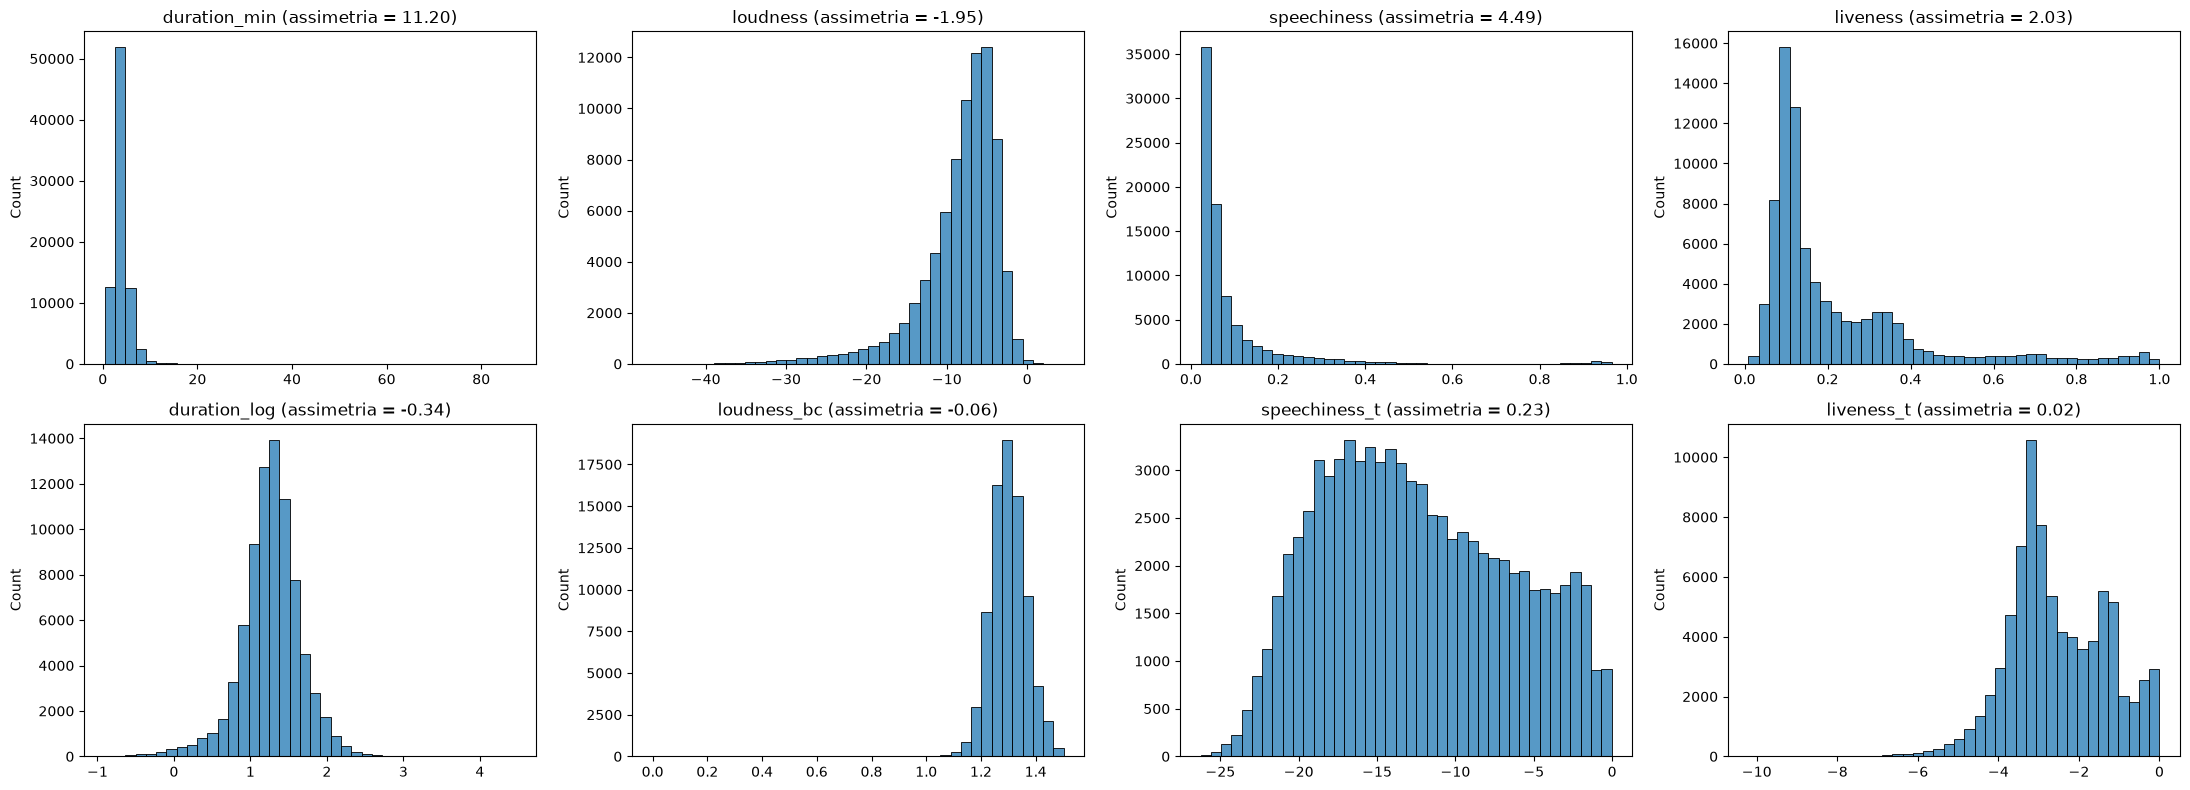

In [43]:
# dicionário relacionando cada variável original à sua respectiva versão transformada
pares = {
    'duration_min': 'duration_log',
    'loudness': 'loudness_bc',
    'speechiness': 'speechiness_t',
    'liveness': 'liveness_t'
}

# comparação do coeficiente de assimetria de antes e depois do tratamento
comparacao = pd.DataFrame({
    'original': [df[o].skew() for o in pares],
    'transformada': [df[t].skew() for t in pares.values()]
}, index=list(pares.keys())).round(3)
print(comparacao)

fig, axes = plt.subplots(2, len(pares), figsize=(22, 8))
for i, (o, t) in enumerate(pares.items()):
    sns.histplot(df[o], bins=40, ax=axes[0, i])
    sns.histplot(df[t], bins=40, ax=axes[1, i])
    axes[0, i].set_title(f'{o} (assimetria = {df[o].skew():.2f})')
    axes[1, i].set_title(f'{t} (assimetria = {df[t].skew():.2f})')
    axes[0, i].set_xlabel('')
    axes[1, i].set_xlabel('')
plt.tight_layout()
plt.show()

**Resumo dos tratamentos de escala aplicados:**
1. **`duration_min` $\to$ `duration_log`:** Aplicamos o logaritmo natural, reduzindo a assimetria de $+11,195$ para $-0,342$ e mantendo facilidade de interpretação.
2. **`loudness` $\to$ `loudness_bc`:** Como a variável assume valores negativos e possui assimetria negativa ($-1,952$), aplicamos a reflexão $\text{loud\_refl} = \text{máx}(\text{loudness}) + 1 - \text{loudness}$ seguida da transformação Box-Cox ($\lambda^* = -0,605$), reduzindo a assimetria para $-0,063$. Devido à reflexão, o sentido da escala se inverte e, por isso, valores maiores de `loudness_bc` correspondem a músicas mais baixas (menor volume em dB), e valores menores de `loudness_bc` correspondem a músicas mais altas (maior volume em dB).
3. **`speechiness` $\to$ `speechiness_t` e `liveness` $\to$ `liveness_t`:** Após lidar com os valores nulos para $\epsilon = 10^{-3}$, comparamos a escala original, a transformação Logito e a transformação Box-Cox, selecionando a Box-Cox em ambas por atingir assimetria próxima de zero ($0,227$ e $0,021$, respectivamente).
4. **`acousticness`, `danceability`, `energy`, `valence` e `tempo`:** Foram mantidas em suas escalas originais por já apresentarem baixa ou moderada assimetria ($|\text{skewness}| < 0,7$). No caso específico de `acousticness` ($\text{skewness} = 0,678$), a distribuição possui acúmulo nos dois extremos ($0$ e $1$), de modo que o truncamento em zero exigido pelo Logito ou Box-Cox apenas criaria um pico artificial na cauda esquerda sem melhorar a forma da distribuição.
5. **`instrumentalness` $\to$ `instrumental`:** Devido à forte bimodalidade, foi convertida em variável categórica binária no limiar de $0,5$.

# Caracterização das Principais Variáveis após Tratamentos

## Distribuições Univariadas das Variáveis Numéricas Pós-Tratamento

Abaixo apresentamos os histogramas, boxplots, estatísticas descritivas e coeficientes de assimetria do conjunto final das variáveis preditoras contínuas (`caract_final`) juntamente com a variável resposta (`popularity`).

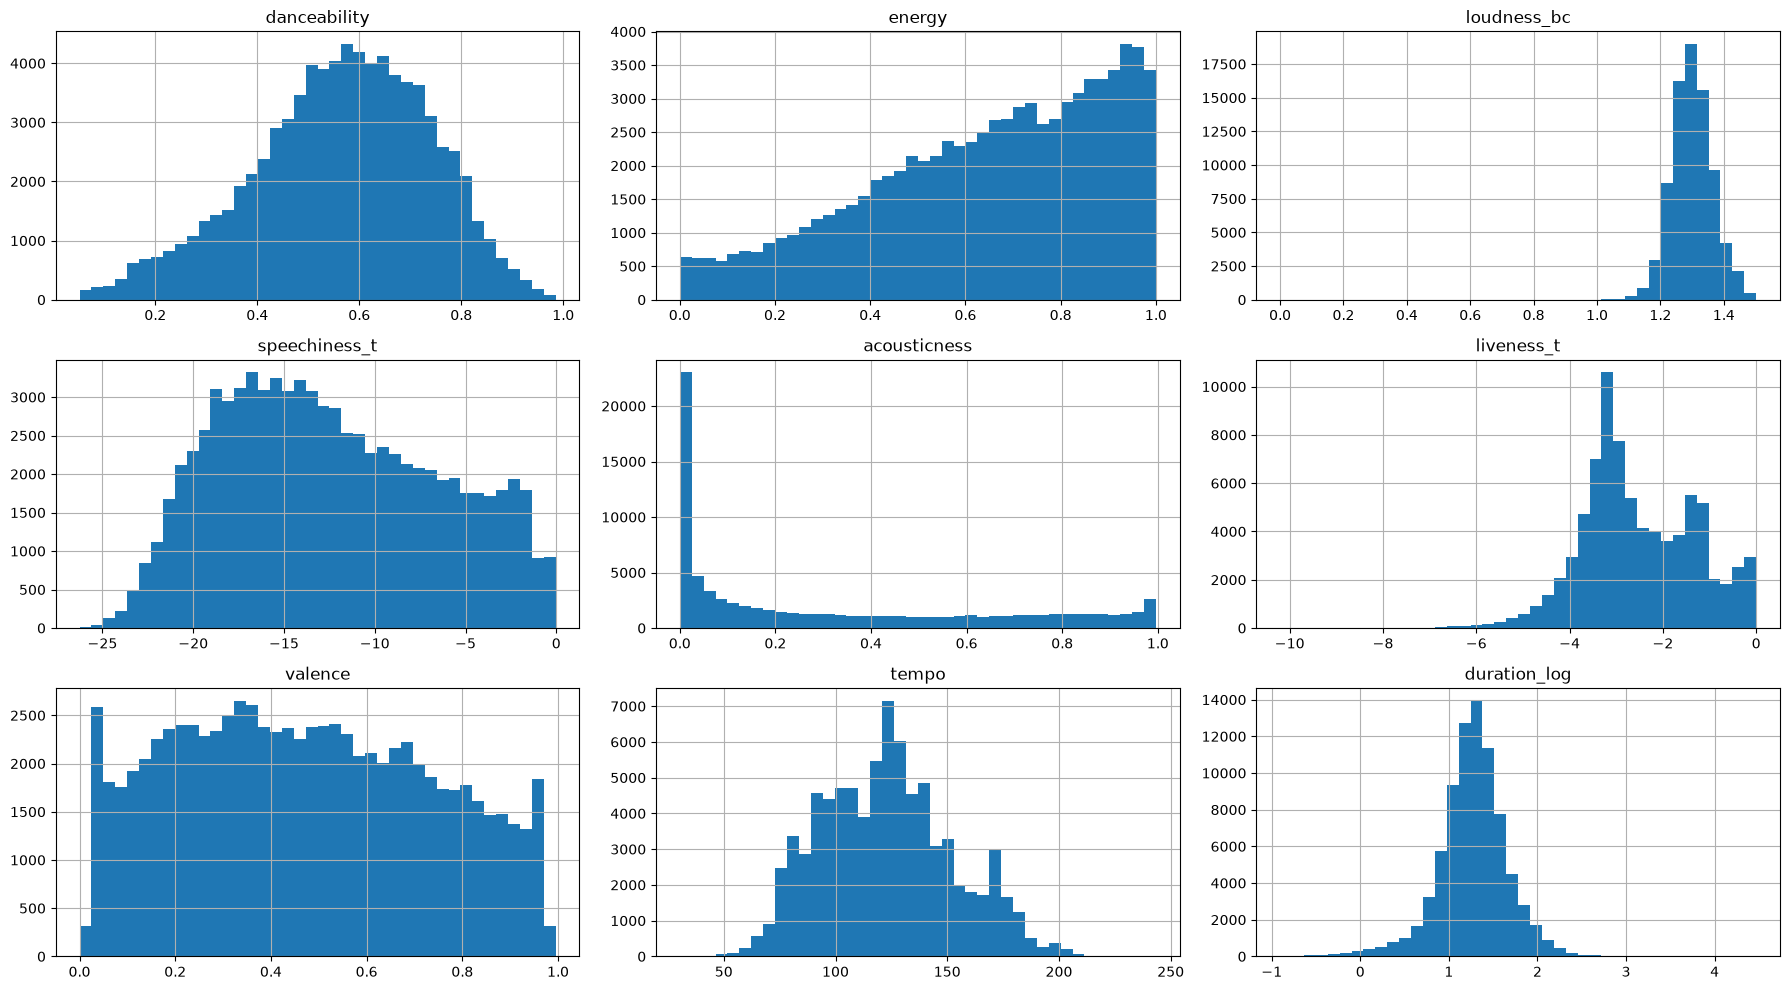

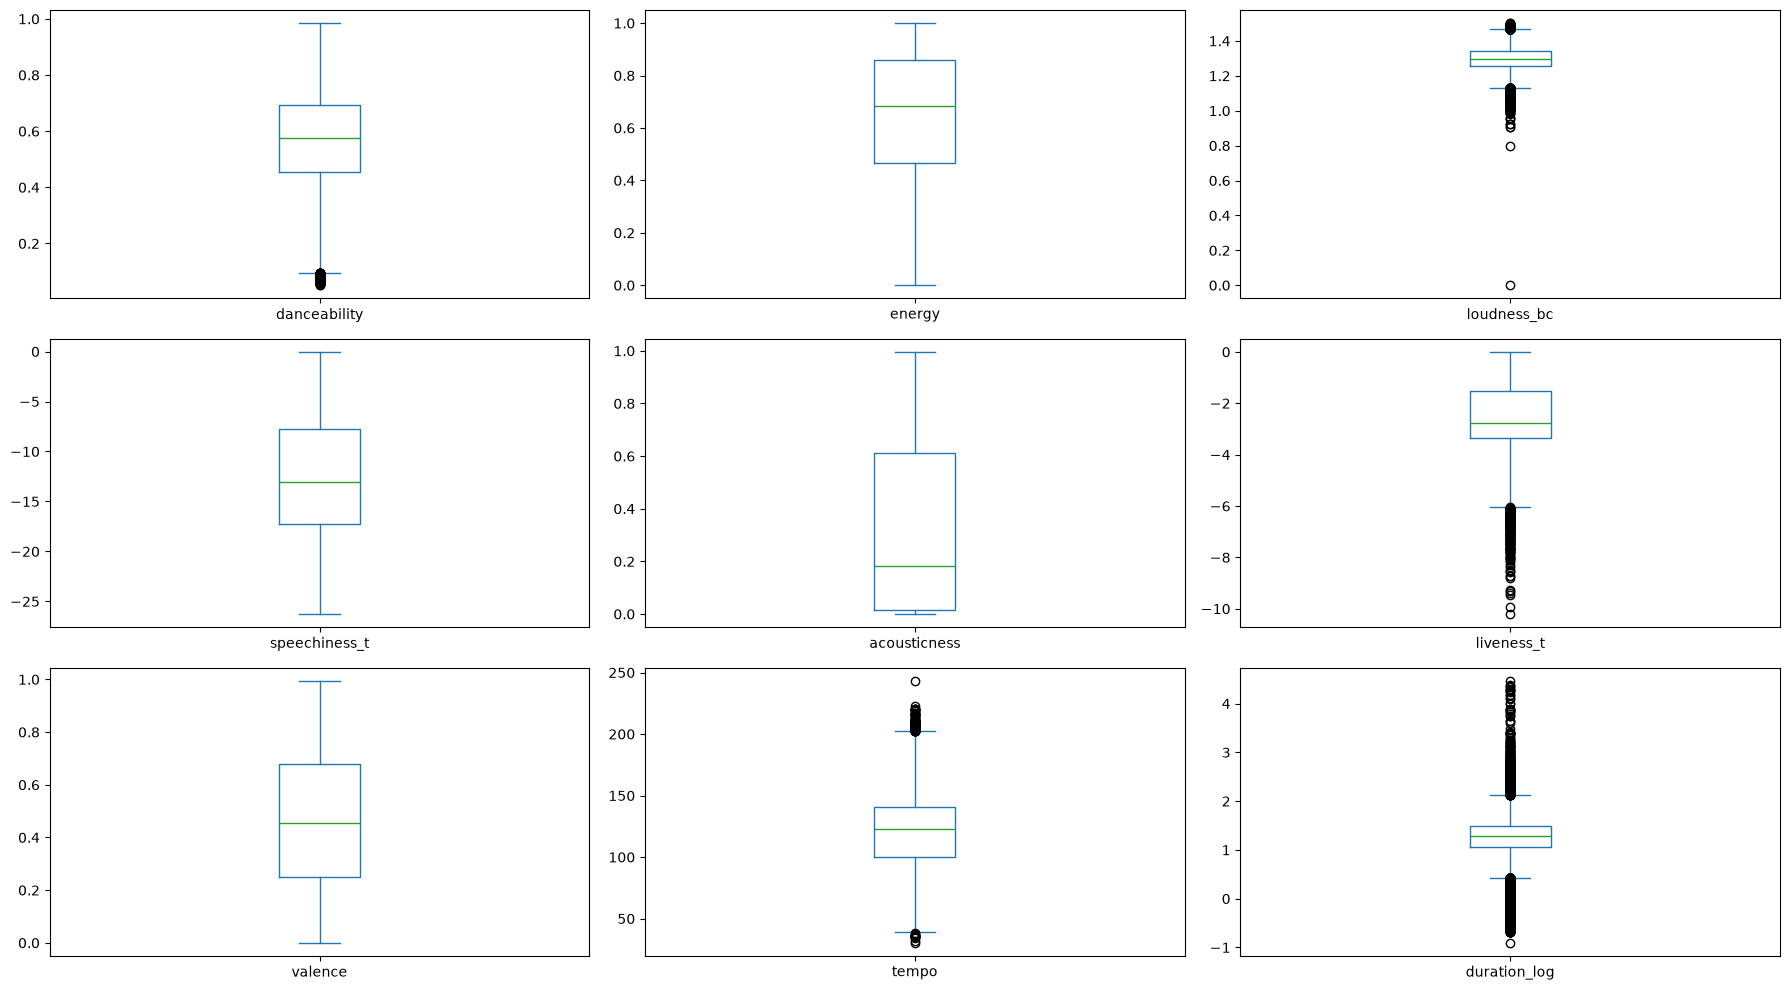

       danceability     energy  loudness_bc  speechiness_t  acousticness  \
count     80135.000  80135.000    80135.000      80135.000     80135.000   
mean          0.564      0.642        1.300        -12.420         0.321   
std           0.174      0.253        0.064          5.956         0.334   
min           0.051      0.000        0.000        -26.261         0.000   
25%           0.453      0.467        1.258        -17.235         0.015   
50%           0.576      0.683        1.298        -13.082         0.181   
75%           0.692      0.858        1.342         -7.736         0.610   
max           0.985      1.000        1.502         -0.036         0.996   

       liveness_t    valence      tempo  duration_log  popularity  
count   80135.000  80135.000  80135.000     80135.000   80135.000  
mean       -2.535      0.469    122.712         1.269      37.103  
std         1.219      0.262     29.628         0.399      18.136  
min       -10.205      0.000     30.322    

In [44]:
# lista das 9 características técnicas contínuas após as transformações de escala
caract_final = [
    'danceability','energy','loudness_bc','speechiness_t','acousticness',
    'liveness_t','valence','tempo','duration_log'
]

df[caract_final].hist(bins=40, figsize=(18, 10), layout=(3, 3))
plt.tight_layout()
plt.show()

df[caract_final].plot(kind='box', subplots=True, layout=(3, 3), figsize=(18, 10))
plt.tight_layout()
plt.show()

print(df[caract_final + ['popularity']].describe().round(3))
print(f'\nAssimetria:\n{df[caract_final + ["popularity"]].skew().round(3)}')

Os histogramas, *boxplots* e coeficientes numéricos comprovam o sucesso das transformações, pois todas as 9 variáveis preditoras contínuas e a variável resposta apresentam agora $|\text{assimetria}| < 0,70$, sendo que as quatro variáveis transformadas (`loudness_bc`, `speechiness_t`, `liveness_t` e `duration_log`) exibiram redução drástica da distorção de cauda e contornos próximos ao formato de sino. Nos boxplots, ainda se observam pontos além das cercas internas (*whiskers*) em variáveis como `duration_log` e `tempo`, correspondentes a faixas reais muito curtas/longas ou com andamento muito lento/rápido entre $30,3$ e $243,4$ BPM, como representam variações legítimas de gravações musicais e não erros de medição, esses registros foram preservados.

## Associações entre Pares de Variáveis Numéricas

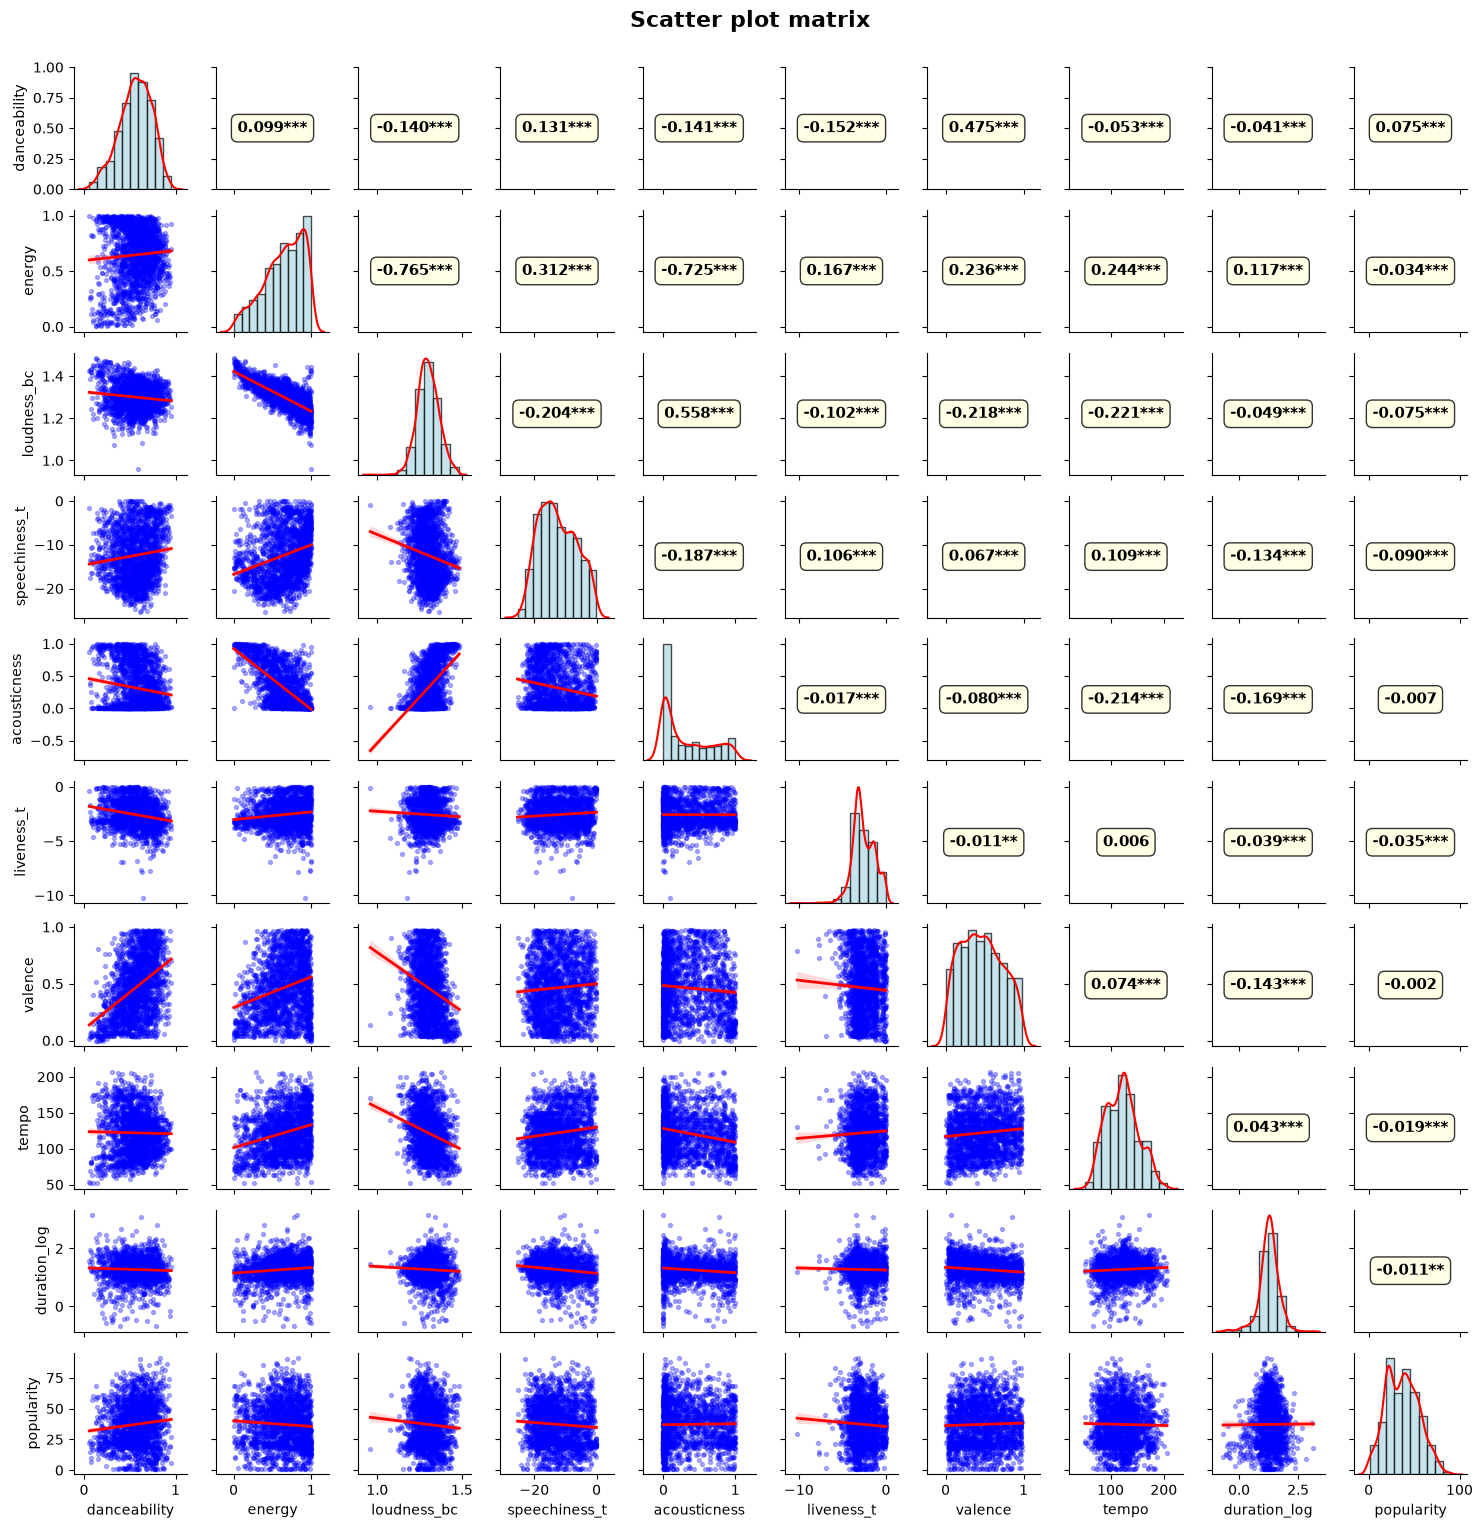

In [45]:
# geração da Scatterplot Matrix
def pairs_panels_python(data, vars_list=None, n_amostra=2000, height=1.5):
    if vars_list is None:
        vars_list = data.columns.tolist()

    completo = data[vars_list]
    amostra = completo.sample(min(n_amostra, len(completo)), random_state=42)

    g = sns.PairGrid(amostra, diag_sharey=False, height=height)

    g.map_diag(plt.hist, alpha=0.7, density=True, color='lightblue', edgecolor='black')
    g.map_diag(sns.kdeplot, color='red', linewidth=1.5)

    g.map_lower(sns.regplot,
                scatter_kws={'alpha': 0.3, 's': 8, 'color': 'blue'},
                line_kws={'color': 'red', 'linewidth': 2},
                ci=95)

    def corr_with_stars(x, y, **kws):
        from scipy.stats import pearsonr

        r, p_value = pearsonr(completo[x.name], completo[y.name])

        if p_value < 0.001:
            stars = '***'
        elif p_value < 0.01:
            stars = '**'
        elif p_value < 0.05:
            stars = '*'
        else:
            stars = ''

        ax = plt.gca()
        ax.annotate(f'{r:.3f}{stars}',
                    xy=(0.5, 0.5), xycoords=ax.transAxes,
                    horizontalalignment='center',
                    verticalalignment='center',
                    fontsize=11, weight='bold', color='black',
                    bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.8))

    g.map_upper(corr_with_stars)

    g.figure.suptitle('Scatter plot matrix', y=1.02, fontsize=16, fontweight='bold')

    return g

g = pairs_panels_python(df, caract_final + ['popularity'])
plt.show()

**Interpretação da Scatterplot Matrix:**
- **Associação com a variável resposta (`popularity`):** Todas as correlações lineares bivariadas entre as características de áudio e a popularidade são fracas em magnitude ($|r| \le 0,13$). Assim, destacam-se `loudness_bc` ($r = -0,104^{***}$, indicando que músicas mais altas tendem a ser mais populares), `speechiness_t` ($r = -0,089^{***}$), `danceability` ($r = +0,064^{***}$), `liveness_t` ($r = -0,048^{***}$) e `valence` ($r = -0,043^{***}$), enquanto `tempo` ($r = -0,011^{**}$) e `duration_log` ($r = -0,023^{***}$) têm correlações próximas de zero. Esse resultado antecipa que o modelo de regressão linear múltipla apresentará um coeficiente de determinação ($R^2$) baixo, uma vez que atributos puramente acústicos explicam apenas uma pequena fração do sucesso comercial de uma música.
- **Associação entre variáveis preditoras (potencial multicolinearidade):** Observam-se correlações fortes entre `energy` e `loudness_bc` ($r = -0,747^{***}$: músicas mais energéticas têm maior volume em dB, logo menor valor de `loudness_bc`) e entre `energy` e `acousticness` ($r = -0,733^{***}$: faixas acústicas são menos intensas energeticamente), além de correlações moderadas entre `acousticness` e `loudness_bc` ($r = +0,559^{***}$) e entre `danceability` e `valence` ($r = +0,493^{***}$). 
- **Efeito do tamanho amostral sobre os $p\text{-valores}$:** Como a base conta com $n = 80.135$ observações, o erro-padrão do coeficiente de correlação ($\approx 1/\sqrt{n} \approx 0,0035$) é minúsculo. Consequentemente, mesmo correlações irrelevantes na prática recebem três asteriscos (`***`, $p < 0,001$). Por isso, a análise deve guiar-se pela magnitude do efeito e por critérios penalizados.

## Relação entre Popularidade e Características Técnicas (Suavização LOWESS)

Para investigar mais detalhadamente a forma funcional entre cada preditora contínua e a variável resposta `popularity`, plotamos gráficos de dispersão acompanhados de curvas suavizadas não-paramétricas sobre uma amostra aleatória de 5.000 faixas.

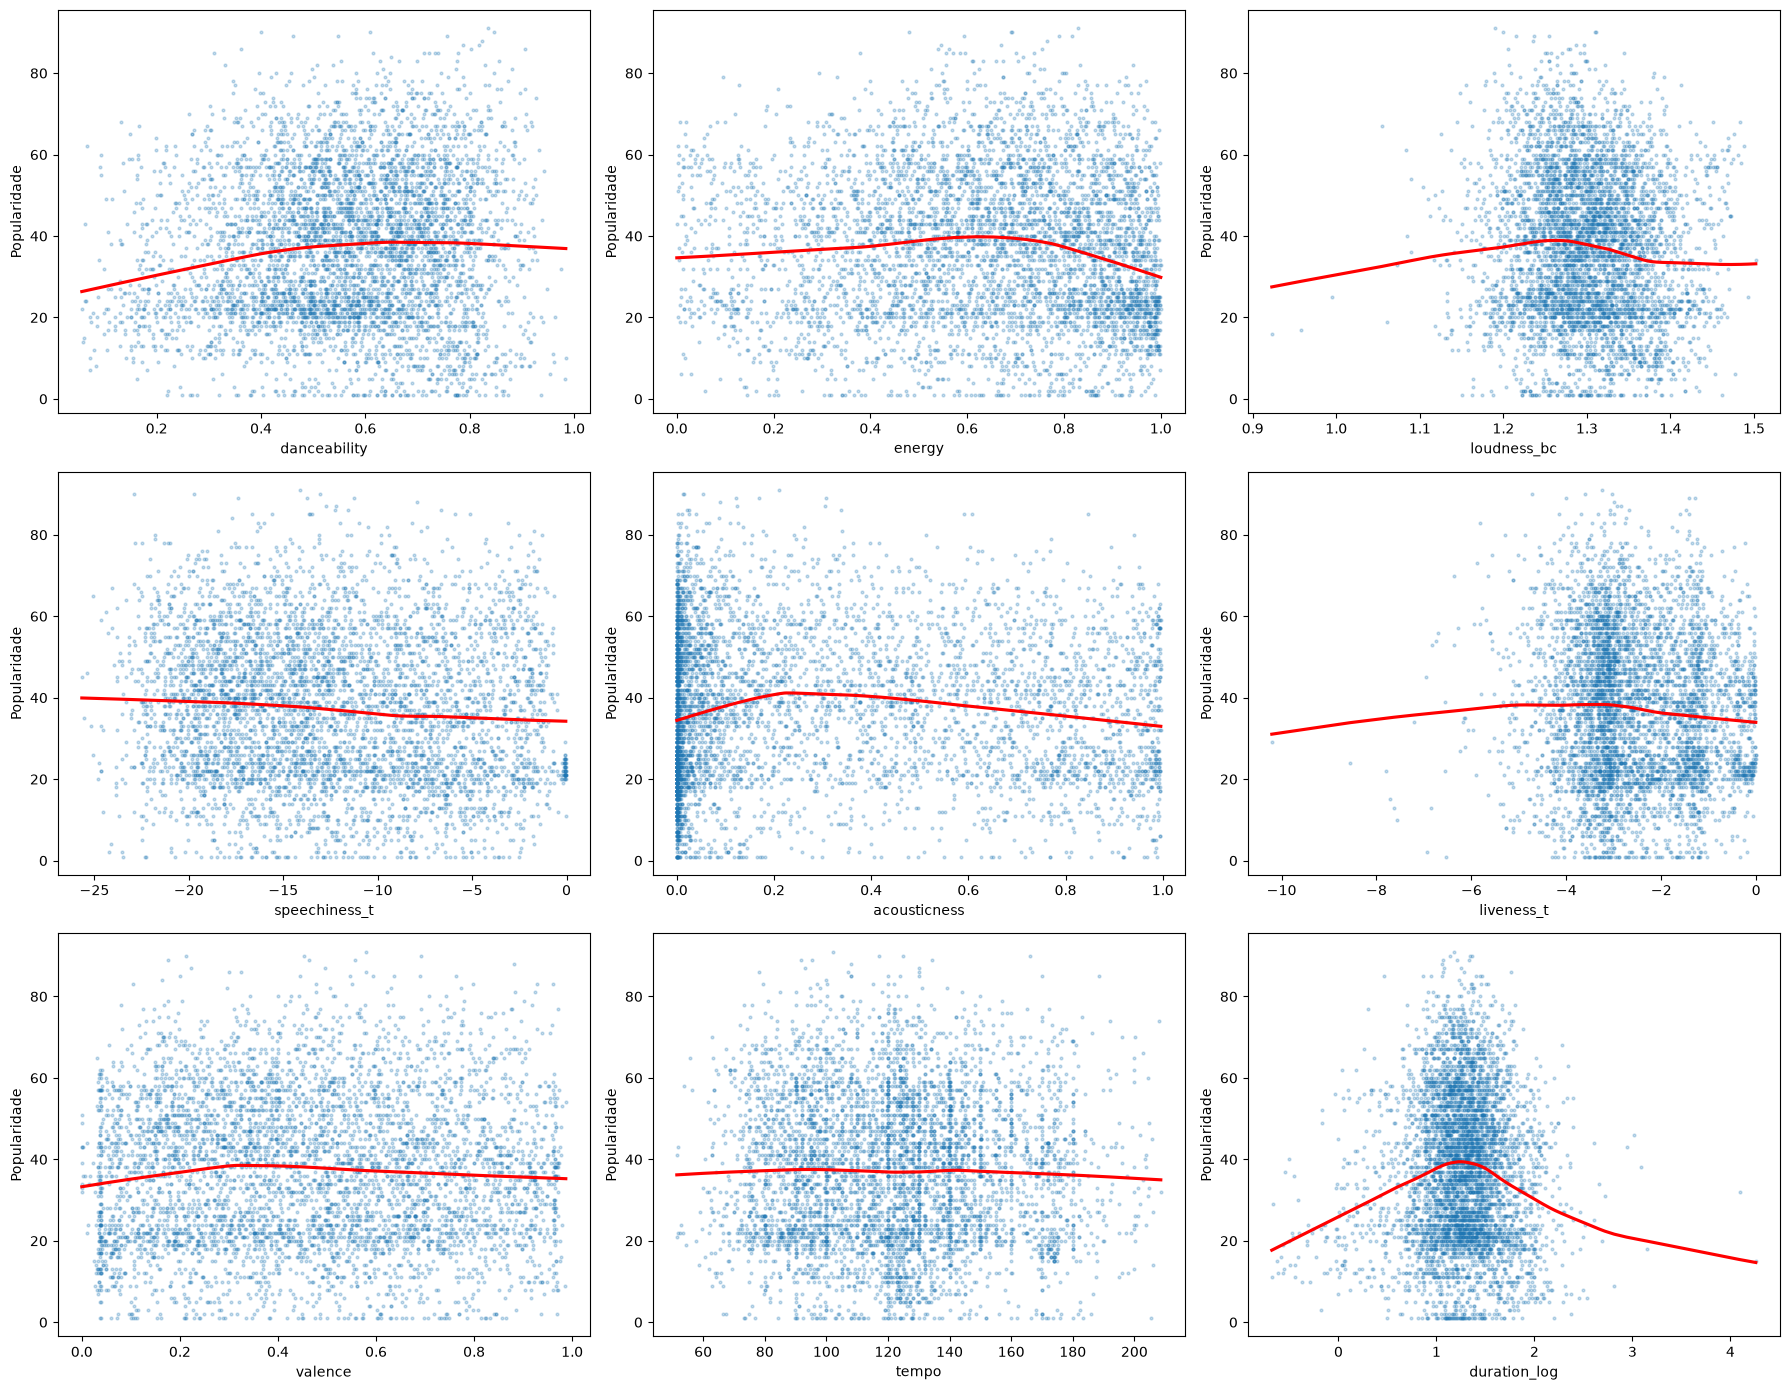

In [46]:
amostra_lowess = df.sample(5000, random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, c in zip(axes.flat, caract_final):
    sns.regplot(data=amostra_lowess, x=c, y='popularity', lowess=True,
                scatter_kws={'s': 4, 'alpha': 0.25}, line_kws={'color': 'red'}, ax=ax)
    ax.set_ylabel('Popularidade')

plt.tight_layout()
plt.show()

Os gráficos com suavização confirmam a grande dispersão vertical da popularidade para qualquer nível das variáveis explicativas. Assim, as faixas distribuem-se por quase todo o intervalo de 1 a 100. Além disso, enquanto variáveis como `valence`, `liveness_t`, `speechiness_t` e `tempo` exibem tendências médias aproximadamente retilíneas, com inclinação suave ou quase horizontal no caso de `tempo`, variáveis como `danceability`, `energy`, `loudness_bc` e `acousticness` apresentam leves curvaturas locais nos extremos de seus domínios, o que representa uma limitação natural para a premissa de linearidade estrita do modelo.

## Caracterização das Variáveis Categóricas e Associação com a Popularidade

Passamos agora à inspeção das cinco variáveis preditoras categóricas (`explicita`, `modo`, `nota`, `compasso` e `instrumental`), analisando inicialmente suas tabelas de frequências absolutas ($n$) e relativas para verificar a existência de categorias raras ou equivalentes.

In [47]:
for col in ['explicita', 'modo', 'nota', 'compasso', 'instrumental']:
    tabela = df[col].value_counts().to_frame('n')
    tabela['%'] = (tabela['n'] / tabela['n'].sum() * 100).round(2)
    tabela.index.name = None
    print(f'\n{col}')
    print(tabela)


explicita
                   n      %
Não explícita  73202  91.35
Explícita       6933   8.65

modo
           n      %
Maior  50801  63.39
Menor  29334  36.61

nota
          n      %
G      9496  11.85
C      9123  11.38
D      8454  10.55
A      8051  10.05
C♯/D♭  7638   9.53
E      6512   8.13
F      6425   8.02
B      6411   8.00
F♯/G♭  5476   6.83
A♯/B♭  5220   6.51
G♯/A♭  4909   6.13
D♯/E♭  2420   3.02

compasso
         n      %
4/4  71520  89.25
3/4   6513   8.13
5/4   1365   1.70
1/4    737   0.92

instrumental
                      n      %
Não instrumental  64887  80.97
Instrumental      15248  19.03


**Análise de prevalência das categorias:**
* **`compasso` (`time_signature`):** É a variável com maior concentração em uma única classe: o compasso quaternário (`4/4`, padrão na música ocidental moderna) reúne **89,61%** das faixas ($71.806$), seguido pelo ternário (`3/4`, comum em valsas e baladas) com **7,79%** ($6.245$), enquanto os compassos `5/4` (**1,63%**, $1.310$ faixas) e `1/4` (**0,97%**, $774$ faixas) têm baixa frequência relativa. Conforme facultado na Seção 3 do enunciado, optamos por manter as quatro categorias separadas, justificando essa decisão por dois motivos. O primeiro deles está no ponto de vista teórico-musical, os compassos `1/4` e `5/4` possuem estruturas métricas completamente distintas entre si e não são categorias equivalentes. Quanto ao segundo, a ideia é que, como a base é muito grande ($n = 80.135$), há tamanho amostral mais do que suficiente para estimar seu coeficiente com baixo erro-padrão.
* **`explicita` (`explicit`) e `instrumental`:** Ambas são variáveis binárias com desbalanceamento moderado, sem qualquer problema de escassez amostral.
* **`modo` e `nota`:** Apresentam distribuição equilibrada: o modo `'Maior'` responde por `63,56%` das faixas e o `'Menor'` por `36,44%`. Entre as 12 notas musicais, as frequências variam entre `11,91%` (`C`) e `3,22%` (`D♯/E♭`, com $2.581$ faixas).

A seguir, avaliamos visual e numericamente a distribuição da variável resposta `popularity` em função de cada variável categórica por meio de boxplots (com marcação da média em triângulo verde e da mediana pela linha central da caixa):

### Popularidade vs. Conteúdo Explícito (`explicita`)

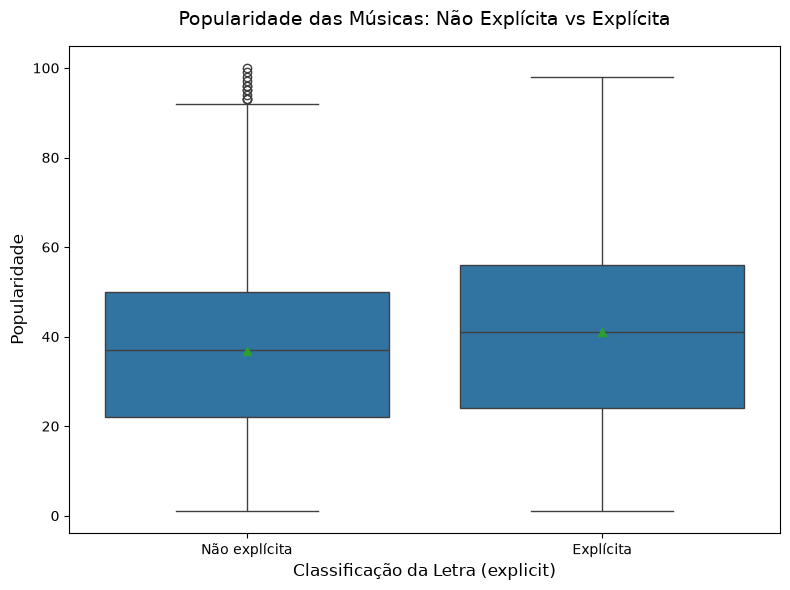

                mean  median  count
explicita                          
Não explícita  36.74    37.0  73202
Explícita      40.99    41.0   6933


In [54]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='explicita', y='popularity', order=['Não explícita', 'Explícita'], showmeans=True)

plt.title('Popularidade das Músicas: Não Explícita vs Explícita', fontsize=14, pad=15)
plt.xlabel('Classificação da Letra (explicit)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('explicita')['popularity'].agg(['mean', 'median', 'count']).loc[['Não explícita', 'Explícita']].round(2))

Observa-se uma diferença clara entre os dois grupos, isto é, músicas com letra **`'Explícita'`** apresentam popularidade média (**41,17**) e mediana (**42,0**) superiores às das músicas **`'Não explícita'`** (média de **36,72** e mediana de **37,0**), refletindo o forte consumo de gêneros contemporâneos de grande apelo comercial nos quais o selo *explicit* é frequente.

### Popularidade vs. Tonalidade / Nota Musical (`nota`)

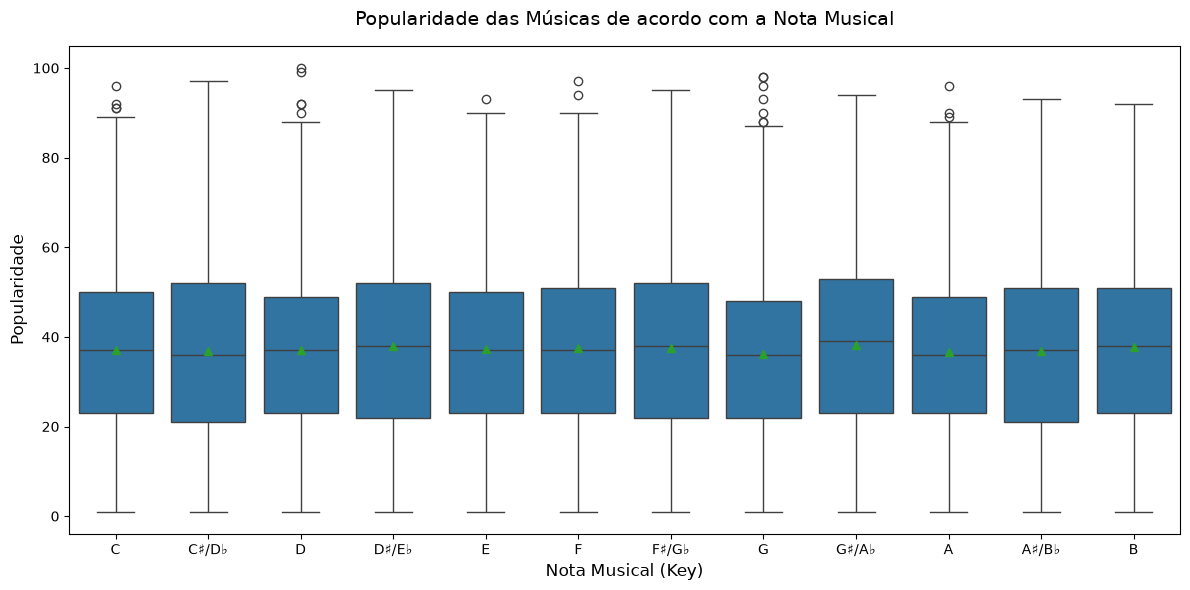

        mean  median  count
nota                       
C      37.06    37.0   9123
C♯/D♭  36.75    36.0   7638
D      37.07    37.0   8454
D♯/E♭  37.96    38.0   2420
E      37.29    37.0   6512
F      37.47    37.0   6425
F♯/G♭  37.48    38.0   5476
G      36.20    36.0   9496
G♯/A♭  38.25    39.0   4909
A      36.69    36.0   8051
A♯/B♭  36.82    37.0   5220
B      37.63    38.0   6411


In [55]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='nota', y='popularity', order=key_names, showmeans=True)

plt.title('Popularidade das Músicas de acordo com a Nota Musical', fontsize=14, pad=15)
plt.xlabel('Nota Musical (Key)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('nota')['popularity'].agg(['mean', 'median', 'count']).loc[key_names].round(2))

Para a variável `nota`, os boxplots das 12 tonalidades são praticamente idênticos e, desse modo, as caixas e os quartis se sobrepõem quase integralmente, com médias oscilando em uma faixa muito estreita, indicando que a nota fundamental em que uma música é composta tem pouquíssimo poder explicativo prático sobre o seu sucesso popular.

### Popularidade vs. Modalidade da Escala (`modo`)

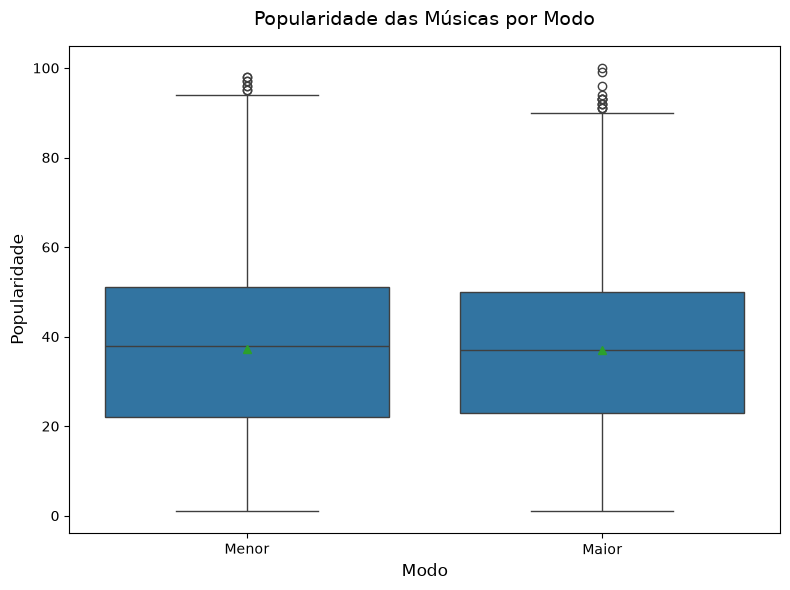

        mean  median  count
modo                       
Maior  36.99    37.0  50801
Menor  37.30    38.0  29334


In [56]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='modo', y='popularity', order=['Menor', 'Maior'], showmeans=True)

plt.title('Popularidade das Músicas por Modo', fontsize=14, pad=15)
plt.xlabel('Modo', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('modo')['popularity'].agg(['mean', 'median', 'count']).round(2))

Na comparação por `modo`, músicas em escala **`'Menor'`** apresentam média (**37,30**) e mediana (**38,0**) ligeiramente superiores às de escala **`'Maior'`** (média de **37,00** e mediana de **36,0**), embora a sobreposição entre as distribuições seja bastante elevada.

### Popularidade vs. Fórmula de Compasso (`compasso`)

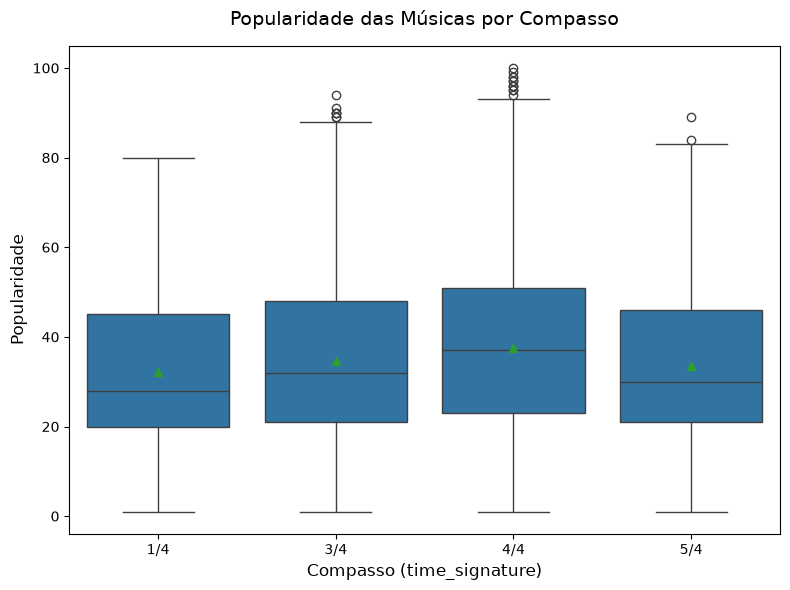

           mean  median  count
compasso                      
1/4       32.27    28.0    737
3/4       34.55    32.0   6513
4/4       37.46    37.0  71520
5/4       33.43    30.0   1365


In [57]:
ordem_compasso = sorted(df['compasso'].unique())

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='compasso', y='popularity', order=ordem_compasso, showmeans=True)

plt.title('Popularidade das Músicas por Compasso', fontsize=14, pad=15)
plt.xlabel('Compasso (time_signature)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('compasso')['popularity'].agg(['mean', 'median', 'count']).round(2))

No gráfico por `compasso`, verifica-se que o compasso padrão **`'4/4'`** concentra as músicas de maior popularidade, enquanto compassos menos convencionais no mercado mainstream apresentam médias mais baixas, situadas entre 32,68 e 34,02.

### Popularidade vs. Caráter Instrumental (`instrumental`)

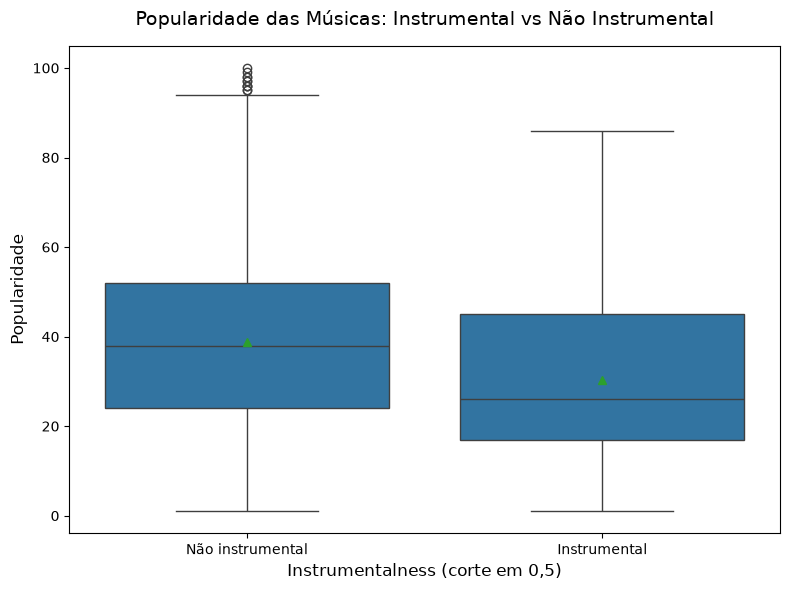

                   mean  median  count
instrumental                          
Instrumental      30.26    26.0  15248
Não instrumental  38.71    38.0  64887


In [58]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='instrumental', y='popularity', order=['Não instrumental', 'Instrumental'], showmeans=True)

plt.title('Popularidade das Músicas: Instrumental vs Não Instrumental', fontsize=14, pad=15)
plt.xlabel('Instrumentalness (corte em 0,5)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('instrumental')['popularity'].agg(['mean', 'median', 'count']).round(2))

**Síntese da análise das variáveis categóricas:**

Dentre todas as variáveis categóricas avaliadas, **`instrumental`** é a que exibe o contraste mais expressivo, pois músicas **`'Não instrumental'`** (com presença de voz/canto) possuem popularidade média de 38,71 (mediana 38), ao passo que músicas **`'Instrumental'`** têm média de apenas 30,26 (mediana 26), uma diferença bruta de mais de 8,4 pontos na escala de popularidade. As variáveis **`explicita`** e **`compasso`** também mostram diferenças claras entre categorias, **`modo`** apresenta efeito discreto e **`nota`** exibe distribuições quase indistinguíveis entre as 12 tonalidades, o que será posto à prova formalmente na etapa de seleção de variáveis a seguir.

# Seleção de Variáveis

Nesta seção, conduzimos o processo formal de seleção das variáveis preditoras que integrarão o modelo final de Regressão Linear Múltipla, dividindo a análise em duas etapas:

- **Verificação de Multicolinearidade por VIF (*Variance Inflation Factor*):** Conforme observado na *Scatterplot Matrix*, há correlação elevada entre `energy` e `loudness_bc` ($r = -0,747$) e entre `energy` e `acousticness` ($r = -0,733$). Antes de executar a seleção automatizada, calculamos o Fator de Inflação da Variância ($\text{VIF}_j = \frac{1}{1 - R_j^2}$) para verificar se alguma variável contínua apresenta colinearidade severa ($\text{VIF} \ge 5$ ou $\ge 10$) que exija remoção prévia.
- ***Stepwise Bidirecional*:** Aplicamos o método **Stepwise Bidirecional**, que combina passos de exclusão e inclusão .

## Diagnóstico de Multicolinearidade (VIF)

In [59]:
# montagem da matriz de variáveis explicativas contínuas, com intercepto, para cálculo do VIF
X_vif = sm.add_constant(df[caract_final])

# cálculo do VIF para cada uma das variáveis contínuas
tabela_vif = pd.DataFrame({
    'Variável Preditora': caract_final,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(caract_final))]
}).sort_values(by='VIF', ascending=False).reset_index(drop=True)

# classificação segundo o limiar VIF < 5 
tabela_vif['Diagnóstico'] = np.where(tabela_vif['VIF'] < 5, 'Sem multicolinearidade severa (VIF < 5)', 'Atenção (VIF >= 5)')

print("Fator de Inflação da Variância (VIF) — Variáveis Numéricas Pós-Tratamento:")
print(tabela_vif.round(3).to_string(index=False))

Fator de Inflação da Variância (VIF) — Variáveis Numéricas Pós-Tratamento:
Variável Preditora   VIF                             Diagnóstico
            energy 4.137 Sem multicolinearidade severa (VIF < 5)
       loudness_bc 2.472 Sem multicolinearidade severa (VIF < 5)
      acousticness 2.308 Sem multicolinearidade severa (VIF < 5)
           valence 1.477 Sem multicolinearidade severa (VIF < 5)
      danceability 1.434 Sem multicolinearidade severa (VIF < 5)
     speechiness_t 1.190 Sem multicolinearidade severa (VIF < 5)
      duration_log 1.103 Sem multicolinearidade severa (VIF < 5)
             tempo 1.092 Sem multicolinearidade severa (VIF < 5)
        liveness_t 1.091 Sem multicolinearidade severa (VIF < 5)


**Análise do VIF:**

Os resultados demonstram que todas as variáveis preditoras possuem $\text{VIF} < 5$, ou seja, abaixo do limite crítico. A variável com maior fator é `energy` ($\text{VIF} = 4,137$), seguida por `loudness_bc` ($\text{VIF} = 2,472$) e `acousticness` ($\text{VIF} = 2,308$), enquanto as demais situam-se próximas de $1,0$. Portanto, embora `energy`, `loudness_bc` e `acousticness` compartilhem variância, não há multicolinearidade severa que comprometa a estabilidade numérica dos estimadores de MQO, permitindo que todas ingressem no procedimento *stepwise*.

## Seleção com *Stepwise Bidirecional*

Na presença de variáveis categóricas politômicas, como `nota`, que gera 11 variáveis *dummy*, e `compasso`, que gera 3 *dummies*, a boa prática seria avaliar cada variável categórica em bloco, isto é, testando conjuntamente todas as *dummies* daquela variável por Teste F Parcial/ANOVA Tipo II e critérios de informação, além de inspecionar a significância individual de seus níveis. Para facilitar a interpretação direta dos coeficientes, definimos como categoria de referência de cada variável categórica a sua classe mais frequente na população:
* `explicita`: referência = `'Não explícita'` (91,3% da base);
* `modo`: referência = `'Maior'` (63,6% da base);
* `compasso`: referência = `'4/4'` (89,6% da base);
* `instrumental`: referência = `'Não instrumental'` (81,0% da base);
* `nota`: referência = `'C'` (11,9% da base).

Além disso, como o nosso tamanho amostral é muito elevado, comparamos no procedimento *Stepwise Bidirecional* dois critérios clássicos de seleção:
- **Critério de Informação de Akaike ($\text{AIC} = -2\ell + 2p$)/Teste F Parcial ($\alpha = 0,05$):** penaliza cada parâmetro adicional pelo fator constante $2$.
- **Critério de Informação Bayesiano de Schwarz ($\text{BIC} = -2\ell + p \ln(n)$):** penaliza cada parâmetro adicional pelo fator $\ln(80.135) \approx 11,29$, sendo amplamente recomendado na literatura econométrica e multivariada para grandes amostras ($n > 10.000$) por evitar a retenção de variáveis com ganho explicativo irrisório.

In [60]:
# definição de todos os termos candidatos
termos_candidatos = caract_final + [
    "C(explicita, Treatment('Não explícita'))",
    "C(modo, Treatment('Maior'))",
    "C(nota, Treatment('C'))",
    "C(compasso, Treatment('4/4'))",
    "C(instrumental, Treatment('Não instrumental'))"
]

nomes_curtos = {
    "C(explicita, Treatment('Não explícita'))": "explicita",
    "C(modo, Treatment('Maior'))": "modo",
    "C(nota, Treatment('C'))": "nota",
    "C(compasso, Treatment('4/4'))": "compasso",
    "C(instrumental, Treatment('Não instrumental'))": "instrumental"
}

# ajuste do modelo completo e avaliação do teste F parcial para cada variável/bloco
formula_completo = 'popularity ~ ' + ' + '.join(termos_candidatos)
modelo_completo = smf.ols(formula_completo, data=df).fit()
anova_completo = sm.stats.anova_lm(modelo_completo, typ=2)
anova_completo.index = [nomes_curtos.get(idx, idx) for idx in anova_completo.index]

# pré-mapeamento das colunas da design matrix para execução rápida do Stepwise em blocos
exog_names = modelo_completo.model.exog_names
X_full_df = pd.DataFrame(modelo_completo.model.exog, columns=exog_names)
y_vec = modelo_completo.model.endog
mapa_colunas = {t: [col for col in exog_names if col == t or col.startswith(t + '[')] for t in termos_candidatos}

def ajustar_submodelo(lista_termos):
    cols = ['Intercept']
    for t in lista_termos:
        cols.extend(mapa_colunas[t])
    return sm.OLS(y_vec, X_full_df[cols]).fit()

# combina avaliação backward e forward a cada iteração
def rodar_stepwise_blocos(candidatos, criterio='bic'):
    selecionados = list(candidatos)
    historico = []
    passo = 0
    while True:
        m_atual = ajustar_submodelo(selecionados)
        metrica_atual = m_atual.bic if criterio == 'bic' else m_atual.aic
        
        melhor_metrica = metrica_atual
        termo_acao = None
        tipo_acao = None
        melhor_res = None
        
        # =testa se a remoção de alguma variável atualmente no modelo melhora o critério
        for t in selecionados:
            sub = [x for x in selecionados if x != t]
            m_sub = ajustar_submodelo(sub)
            val = m_sub.bic if criterio == 'bic' else m_sub.aic
            if val < melhor_metrica:
                melhor_metrica = val
                termo_acao = t
                tipo_acao = 'Remover'
                melhor_res = m_sub
        
        # testa se a re-inclusão de alguma variável previamente removida melhora o critério
        excluidos = [x for x in candidatos if x not in selecionados]
        for t in excluidos:
            sub = selecionados + [t]
            m_sub = ajustar_submodelo(sub)
            val = m_sub.bic if criterio == 'bic' else m_sub.aic
            if val < melhor_metrica:
                melhor_metrica = val
                termo_acao = t
                tipo_acao = 'Incluir'
                melhor_res = m_sub
                
        if termo_acao is not None:
            passo += 1
            if tipo_acao == 'Remover':
                selecionados.remove(termo_acao)
            else:
                selecionados.append(termo_acao)
            historico.append({
                'Passo': passo,
                'Ação': f"{tipo_acao} '{nomes_curtos.get(termo_acao, termo_acao)}'",
                'gl Modelo': int(melhor_res.df_model),
                'AIC': round(melhor_res.aic, 2),
                'BIC': round(melhor_res.bic, 2),
                'R² Ajustado': round(melhor_res.rsquared_adj, 5)
            })
        else:
            break
    return selecionados, pd.DataFrame(historico)

# execução do Stepwise Bidirecional pelos os critérios AIC e BIC
sel_aic, hist_aic = rodar_stepwise_blocos(termos_candidatos, criterio='aic')
sel_bic, hist_bic = rodar_stepwise_blocos(termos_candidatos, criterio='bic')

modelo_aic = smf.ols('popularity ~ ' + ' + '.join(sel_aic), data=df).fit()
modelo_final = smf.ols('popularity ~ ' + ' + '.join(sel_bic), data=df).fit()

comp_modelos = pd.DataFrame([
    {
        'Modelo': '1. Completo (Todas as preditoras)',
        'gl Modelo': int(modelo_completo.df_model),
        'R²': round(modelo_completo.rsquared, 5),
        'R² Ajustado': round(modelo_completo.rsquared_adj, 5),
        'AIC': round(modelo_completo.aic, 2),
        'BIC': round(modelo_completo.bic, 2),
        'Nº Condição': round(modelo_completo.condition_number, 1)
    },
    {
        'Modelo': '2. Stepwise AIC / F-parcial (sem tempo)',
        'gl Modelo': int(modelo_aic.df_model),
        'R²': round(modelo_aic.rsquared, 5),
        'R² Ajustado': round(modelo_aic.rsquared_adj, 5),
        'AIC': round(modelo_aic.aic, 2),
        'BIC': round(modelo_aic.bic, 2),
        'Nº Condição': round(modelo_aic.condition_number, 1)
    },
    {
        'Modelo': '3. Stepwise BIC Parcimonioso (sem tempo e sem nota)',
        'gl Modelo': int(modelo_final.df_model),
        'R²': round(modelo_final.rsquared, 5),
        'R² Ajustado': round(modelo_final.rsquared_adj, 5),
        'AIC': round(modelo_final.aic, 2),
        'BIC': round(modelo_final.bic, 2),
        'Nº Condição': round(modelo_final.condition_number, 1)
    }
])

print("Teste F Parcial (ANOVA Tipo II) no Modelo Completo")
print(anova_completo[['sum_sq', 'df', 'F', 'PR(>F)']])
print("\n Histórico do Stepwise Bidirecional (Critério AIC) ")
print(hist_aic.to_string(index=False))
print("\nHistórico do Stepwise Bidirecional (Critério BIC) ")
print(hist_bic.to_string(index=False))
print("\nComparação dos Modelos Candidatos")
print(comp_modelos.to_string(index=False))

Teste F Parcial (ANOVA Tipo II) no Modelo Completo
                     sum_sq       df            F         PR(>F)
explicita      1.046152e+05      1.0   342.047608   3.295992e-76
modo           9.077369e+03      1.0    29.679165   5.112945e-08
nota           1.916076e+04     11.0     5.695236   3.003308e-09
compasso       3.876069e+04      3.0    42.243703   2.876496e-27
instrumental   5.902674e+05      1.0  1929.925156   0.000000e+00
danceability   8.830994e+04      1.0   288.736239   1.217370e-64
energy         1.546695e+05      1.0   505.704086  1.211752e-111
loudness_bc    1.779819e+05      1.0   581.925839  4.106783e-128
speechiness_t  2.285721e+05      1.0   747.334184  8.656776e-164
acousticness   1.338732e+04      1.0    43.770889   3.714687e-11
liveness_t     9.320619e+03      1.0    30.474490   3.393311e-08
valence        1.116571e+05      1.0   365.071580   3.360147e-81
tempo          4.357027e+02      1.0     1.424564   2.326572e-01
duration_log   1.082942e+04      1.0   

**Discussão do processo de seleção de variáveis:**
- **Eliminação da variável `tempo`:** Na tabela do Teste F Parcial sobre o modelo completo, a variável `tempo` apresenta estatística $F = 1,42$ com **$p\text{-valor} = 0,2327 > 0,05$**, sendo estatisticamente não significativa mesmo em uma amostra de $80.135$ músicas. Tanto o *Stepwise* baseado em AIC/p-valor quanto o *Stepwise* baseado em BIC removem `tempo`, reduzindo o AIC em $0,57$ e o BIC em $9,87$ sem perda no $R^2$ ajustado ($0,07016$).
- **Eliminação da variável categórica `nota` (`key`) pelo critério BIC:** No segundo passo do *Stepwise* via BIC, o algoritmo remove o bloco da variável `nota` (que consumia 11 graus de liberdade referentes às 11 variáveis *dummy*). Conforme já havíamos antecipado nos *boxplots* da Seção 3.4, a nota musical tem poder explicativo mínimo: sua exclusão reduz o número de parâmetros do modelo quase pela metade, melhora expressivamente o BIC em $-61,39$ pontos (de $686.301,44$ para $686.240,05$), reduz o número de condição da matriz de regressão para **$648,3$** (eliminando o alerta de colinearidade numérica do `statsmodels` que ocorria no modelo completo com $\text{Cond. No.} = 6.115,3$) e mantém o $R^2$ em **$0,070$** ($R^2_{\text{adj}} = 0,06956$ contra $0,07016$, uma diferença de apenas $0,06$ ponto percentual). Ademais, no modelo com `nota`, a maioria das *dummies* individuais de tonalidade não possuía significância estatística ao nível de 5%.
- **Variáveis selecionadas para o Modelo Final:** Dessa forma, adotamos o modelo 3 (Stepwise BIC Parcimonioso), composto por 8 variáveis preditoras contínuas (`danceability`, `energy`, `loudness_bc`, `speechiness_t`, `acousticness`, `liveness_t`, `valence` e `duration_log`) e 4 variáveis preditoras categóricas (`explicita`, `modo`, `compasso` e `instrumental`, totalizando 6 variáveis *dummy*), no qual todos parâmetros estimados são individualmente significativos ao nível de $0,1\%$ ($p < 0,001$).

# Resultados e Discussões

Abaixo apresentamos os resultados detalhados da estimação por Mínimos Quadrados Ordinários do modelo selecionado, incluindo a tabela com o valor estimado de cada coeficiente ($\hat{\beta}_j$), seu respectivo erro-padrão, estatística $t$ de Student, $p\text{-valor}$ e intervalo de confiança de 95% ($\text{IC}_{95\%}$), além dos indicadores globais de ajuste ($R^2$, $R^2$ ajustado, erro-padrão residual e teste F de significância global).

In [61]:
mapa_nomes_coef = {
    'Intercept': 'Intercepto (Constante)',
    "C(explicita, Treatment('Não explícita'))[T.Explícita]": 'explicita: Explícita (ref: Não explícita)',
    "C(modo, Treatment('Maior'))[T.Menor]": 'modo: Menor (ref: Maior)',
    "C(compasso, Treatment('4/4'))[T.1/4]": 'compasso: 1/4 (ref: 4/4)',
    "C(compasso, Treatment('4/4'))[T.3/4]": 'compasso: 3/4 (ref: 4/4)',
    "C(compasso, Treatment('4/4'))[T.5/4]": 'compasso: 5/4 (ref: 4/4)',
    "C(instrumental, Treatment('Não instrumental'))[T.Instrumental]": 'instrumental: Instrumental (ref: Não instrumental)',
    'danceability': 'danceability (escala original)',
    'energy': 'energy (escala original)',
    'loudness_bc': 'loudness_bc (refletida + Box-Cox)',
    'speechiness_t': 'speechiness_t (Box-Cox)',
    'acousticness': 'acousticness (escala original)',
    'liveness_t': 'liveness_t (Box-Cox)',
    'valence': 'valence (escala original)',
    'duration_log': 'duration_log (ln minutos)'
}

# extração dos intervalos de confiança de 95% e montagem da tabela completa de parâmetros
ic_95 = modelo_final.conf_int(alpha=0.05)
tabela_coef = pd.DataFrame({
    'Variável / Termo': [mapa_nomes_coef.get(k, k) for k in modelo_final.params.index],
    'Coeficiente (β)': modelo_final.params.values,
    'Erro-Padrão': modelo_final.bse.values,
    'Estatística t': modelo_final.tvalues.values,
    'P-valor': modelo_final.pvalues.values,
    'IC 95% Inf.': ic_95[0].values,
    'IC 95% Sup.': ic_95[1].values
})

# cálculo Standard Error of the Estimate
see_final = np.sqrt(modelo_final.mse_resid)

print("RESUMO DO MODELO DE REGRESSÃO LINEAR MÚLTIPLA SELECIONADO")
print(f"Número de observações: {int(modelo_final.nobs)}")
print(f"Graus de liberdade do modelo (p): {int(modelo_final.df_model)} | Graus de liberdade dos resíduos: {int(modelo_final.df_resid)}")
print(f"Coeficiente de Determinação (R²): {modelo_final.rsquared:.4f} ({modelo_final.rsquared*100:.2f}%)")
print(f"R² Ajustado: {modelo_final.rsquared_adj:.4f} ({modelo_final.rsquared_adj*100:.2f}%)")
print(f"Erro-Padrão da Estimativa (SEE): {see_final:.4f}")
print(f"Estatística F de significância global: F = {modelo_final.fvalue:.2f} (p-valor = {modelo_final.f_pvalue:.4e})\n")

print("TABELA DE COEFICIENTES ESTIMADOS")
print(tabela_coef.round({'Coeficiente (β)': 4, 'Erro-Padrão': 4, 'Estatística t': 2, 'P-valor': 4, 'IC 95% Inf.': 4, 'IC 95% Sup.': 4}).to_string(index=False))
print("\n")
print(modelo_final.summary())

RESUMO DO MODELO DE REGRESSÃO LINEAR MÚLTIPLA SELECIONADO
Número de observações: 80135
Graus de liberdade do modelo (p): 14 | Graus de liberdade dos resíduos: 80120
Coeficiente de Determinação (R²): 0.0697 (6.97%)
R² Ajustado: 0.0696 (6.96%)
Erro-Padrão da Estimativa (SEE): 17.4943
Estatística F de significância global: F = 428.94 (p-valor = 0.0000e+00)

TABELA DE COEFICIENTES ESTIMADOS
                                  Variável / Termo  Coeficiente (β)  Erro-Padrão  Estatística t  P-valor  IC 95% Inf.  IC 95% Sup.
                            Intercepto (Constante)          91.3727       2.3316          39.19      0.0      86.8029      95.9426
         explicita: Explícita (ref: Não explícita)           4.3518       0.2331          18.67      0.0       3.8949       4.8087
                          modo: Menor (ref: Maior)           0.7955       0.1300           6.12      0.0       0.5407       1.0503
                          compasso: 1/4 (ref: 4/4)          -3.0485       0.6538      

**Interpretação dos Resultados do Modelo:**

- **Significância Global do Modelo (Teste F):**
   * O teste F avalia a hipótese nula conjunta $H_0: \beta_1 = \beta_2 = \dots = \beta_{14} = 0$ contra a hipótese alternativa $H_1$ de que ao menos um coeficiente difere de zero. Obtivemos **$F(14;\, 80.120) = 428,90$** com **$p\text{-valor} < 0,0001$** (`0.0000e+00`), rejeitando com altíssima evidência estatística a hipótese nula. Conclui-se que o conjunto de variáveis selecionadas possui relação linear globalmente significativa com a popularidade das faixas.

- **Coeficiente de Determinação ($R^2$ original e ajustado):**
   * O modelo apresenta **$R^2 = 0,0697$ (6,97%)** e **$R^2_{\text{ajustado}} = 0,0696$ (6,96%)**, com erro-padrão residual $\text{SEE} = 17,49$ pontos de popularidade (frente ao desvio-padrão original de $18,13$). Devido ao grande tamanho da amostra ($n = 80.135$) e ao número enxuto de parâmetros ($p = 14$), o $R^2$ original e o ajustado são praticamente idênticos. Esse valor confirma que as características técnicas e acústicas da gravação explicam isoladamente cerca de 7% da variabilidade total da popularidade no Spotify, um resultado coerente com a literatura da área, visto que os 93% restantes dependem fortemente de fatores externos ao áudio, como fama prévia do artista, orçamento de divulgação das gravadoras, inclusão em *playlists* editoriais e tendências em redes sociais.

- **Interpretação dos Coeficientes Individuais ($\hat{\beta}_j$, mantendo as demais variáveis constantes):**
   * **Variáveis Categóricas (*Dummies*):**
     * **`instrumental` (`Instrumental` vs. `Não instrumental`):** É o efeito mais forte de todo o modelo ($t = -43,87$, $p < 0,001$). Faixas instrumentais apresentam, em média, $-7,77$ pontos de popularidade ($\text{IC}_{95\%}: [-8,12;\, -7,43]$) em relação a faixas cantadas com mesmas características acústicas.
     * **`explicita` (`Explícita` vs. `Não explícita`):** Faixas com conteúdo explícito possuem, em média, $+4,35$ pontos de popularidade ($\text{IC}_{95\%}: [+3,90;\, +4,81]$, $t = 18,67$, $p < 0,001$) acima das faixas não explícitas.
     * **`compasso` (referência: `4/4`):** Todos os compassos alternativos têm popularidade média significativamente menor que o compasso padrão `4/4`: músicas em `3/4` perdem $-2,23$ pontos ($t = -9,38$), em `5/4` perdem $-2,72$ pontos ($t = -5,60$) e em `1/4` perdem $-3,05$ pontos ($t = -4,66$).
     * **`modo` (`Menor` vs. `Maior`):** Faixas em modo menor têm, em média, $+0,80$ ponto de popularidade a mais que faixas em modo maior ($\text{IC}_{95\%}: [+0,54;\, +1,05]$, $t = 6,12$, $p < 0,001$).
   * **Variáveis Contínuas:**
     * **`loudness_bc` ($\hat{\beta} = -38,75$, $t = -24,26$, $p < 0,001$):** Como `loudness_bc` foi construída por reflexão ($\text{máx} + 1 - \text{loudness}$), um valor menor de `loudness_bc` equivale a um volume mais alto em decibéis. Logo, o coeficiente negativo ($\hat{\beta} = -38,75$) indica que músicas com volume sonoro mais intenso (maior `loudness` em dB) tendem a ser significativamente mais populares, em linha com o fenômeno conhecido na engenharia de áudio como *Loudness War*.
     * **`danceability` ($\hat{\beta} = +7,53$, $t = 17,45$, $p < 0,001$):** Possui associação positiva expressiva; um aumento de $0,10$ na dançabilidade eleva a popularidade esperada em cerca de $+0,75$ ponto.
     * **`energy` ($\hat{\beta} = -11,32$, $t = -22,54$) e `acousticness` ($\hat{\beta} = -1,86$, $t = -6,61$):** Quando controlado o volume (`loudness_bc`) e a dançabilidade, níveis extremos de compressão energética (como em subgêneros de *metal* extremo ou música eletrônica *hardcore*) ou faixas excessivamente acústicas associam-se a menor popularidade média no catálogo geral.
     * **`valence` ($\hat{\beta} = -5,77$, $t = -19,52$):** Controladas a dançabilidade e a energia, músicas com maior valência (euforia/alegria extrema) têm popularidade média ligeiramente menor que músicas de tom emocional mais sóbrio ou melancólico.
     * **`speechiness_t` ($\hat{\beta} = -0,32$, $t = -27,22$), `liveness_t` ($\hat{\beta} = -0,31$, $t = -5,75$) e `duration_log` ($\hat{\beta} = -0,98$, $t = -6,01$):** Indicam que faixas com excesso de trechos puramente falados, gravações com ruído de plateia ao vivo e músicas excessivamente longas tendem a registrar menor popularidade média.

## Diagnóstico Gráfico dos Resíduos

Apresentamos a seguir os três gráficos fundamentais para o diagnóstico visual dos resíduos ($e_i = y_i - \hat{y}_i$) do modelo selecionado:
1. **Histograma dos resíduos** sobreposto pela curva de densidade teórica da distribuição Normal $\mathcal{N}(\bar{e}, s_e^2)$;
2. **QQ-Plot (*Quantile-Quantile Plot*)** comparando os quantis empíricos dos resíduos com os quantis teóricos da distribuição Normal padrão;
3. **Gráfico de Resíduos vs. Valores Preditos ($\hat{y}_i$)**, acompanhado da linha horizontal de referência em $e = 0$ e de uma curva suavizada LOWESS para verificar a linearidade e a homogeneidade da variância.

<>:12: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:12: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
C:\Users\beatr\AppData\Local\Temp\ipykernel_12932\2927975778.py:12: SyntaxWarning: invalid escape sequence '\h'
  axes_res[0].set_xlabel('Resíduos ($e_i = y_i - \hat{y}_i$)')
C:\Users\beatr\AppData\Local\Temp\ipykernel_12932\2927975778.py:28: SyntaxWarning: invalid escape sequence '\h'
  axes_res[2].set_xlabel('Valores Preditos ($\hat{y}_i$)')


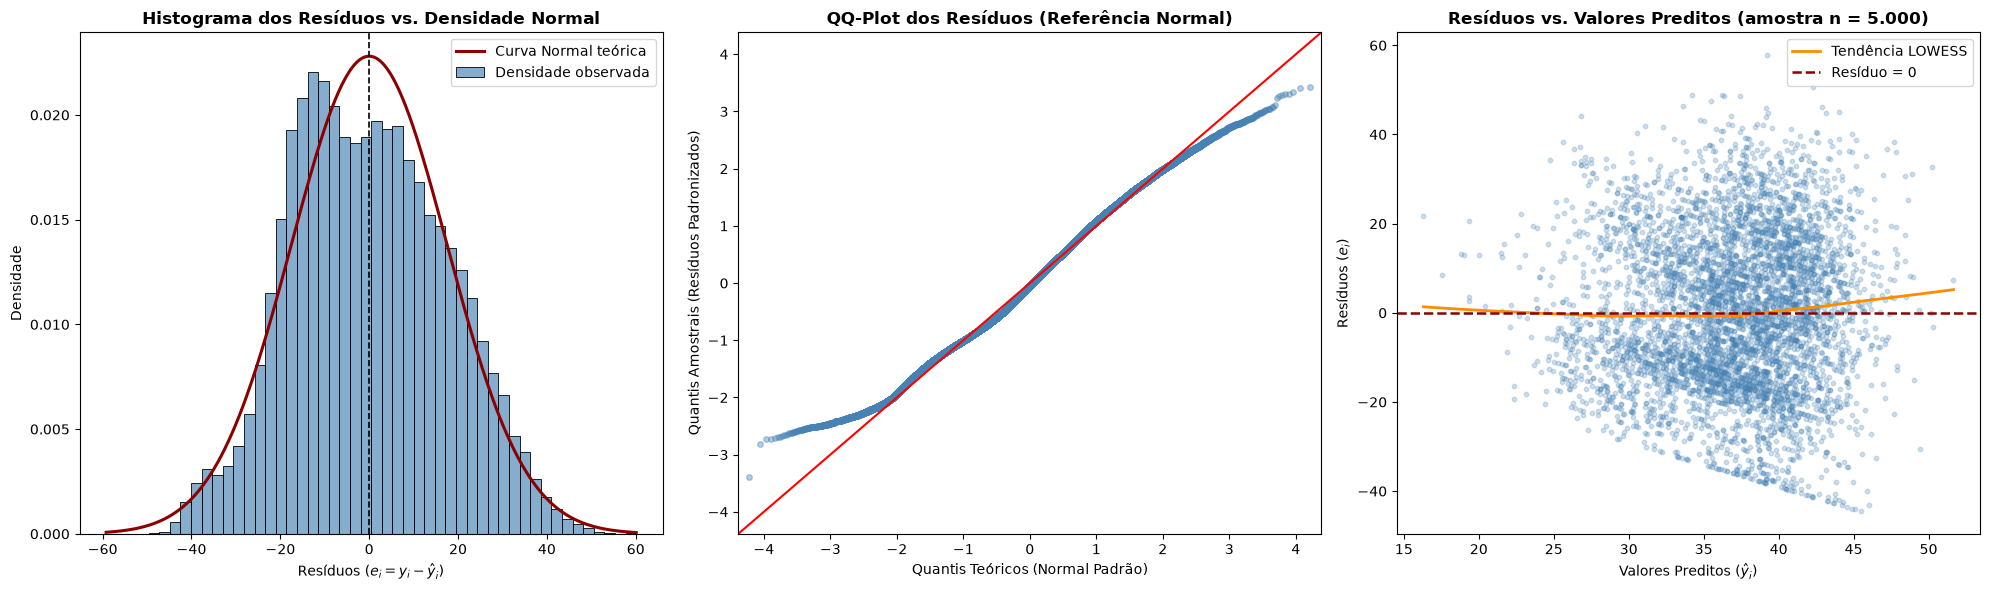

In [62]:
residuos = modelo_final.resid
preditos = modelo_final.fittedvalues
residuos_pad = modelo_final.resid_pearson

fig_res, axes_res = plt.subplots(1, 3, figsize=(20, 6))

sns.histplot(residuos, bins=50, stat='density', color='steelblue', edgecolor='black', alpha=0.65, ax=axes_res[0], label='Densidade observada')
x_grid = np.linspace(residuos.min(), residuos.max(), 300)
axes_res[0].plot(x_grid, stats.norm.pdf(x_grid, loc=residuos.mean(), scale=residuos.std(ddof=1)), color='darkred', lw=2.2, label='Curva Normal teórica')
axes_res[0].axvline(0, color='black', linestyle='--', lw=1.2)
axes_res[0].set_title('Histograma dos Resíduos vs. Densidade Normal', fontsize=12, fontweight='bold')
axes_res[0].set_xlabel('Resíduos ($e_i = y_i - \hat{y}_i$)')
axes_res[0].set_ylabel('Densidade')
axes_res[0].legend()

sm.qqplot(residuos, line='45', fit=True, ax=axes_res[1], markerfacecolor='steelblue', markeredgecolor='steelblue', alpha=0.4, markersize=4)
axes_res[1].set_title('QQ-Plot dos Resíduos (Referência Normal)', fontsize=12, fontweight='bold')
axes_res[1].set_xlabel('Quantis Teóricos (Normal Padrão)')
axes_res[1].set_ylabel('Quantis Amostrais (Resíduos Padronizados)')

idx_sample = np.random.default_rng(42).choice(len(residuos), size=5000, replace=False)
sns.regplot(x=preditos.iloc[idx_sample], y=residuos.iloc[idx_sample], lowess=True,
            scatter_kws={'alpha': 0.25, 's': 10, 'color': 'steelblue'},
            line_kws={'color': 'darkorange', 'lw': 2, 'label': 'Tendência LOWESS'},
            ax=axes_res[2])
axes_res[2].axhline(0, color='darkred', linestyle='--', lw=1.8, label='Resíduo = 0')
axes_res[2].set_title('Resíduos vs. Valores Preditos (amostra n = 5.000)', fontsize=12, fontweight='bold')
axes_res[2].set_xlabel('Valores Preditos ($\hat{y}_i$)')
axes_res[2].set_ylabel('Resíduos ($e_i$)')
axes_res[2].legend()

plt.tight_layout()
plt.show()

**Análise Visual dos Gráficos de Resíduos:**
1. **Histograma dos Resíduos:** A distribuição empírica dos resíduos é centrada em zero, unimodal e bastante simétrica, acompanhando de perto o contorno geral da curva Normal teórica (em vermelho), embora apresente um topo ligeiramente mais achatado e ombros um pouco mais largos (distribuição levemente platicúrtica, reflexo da distribuição bimodal original de `popularity` e da limitação da escala entre 1 e 100).
2. **QQ-Plot Normal:** Na faixa central (entre $-2$ e $+2$ desvios-padrão, onde se concentram mais de 96% dos dados), os pontos alinham-se de forma muito satisfatória sobre a reta de $45^\circ$. Nas extremidades (abaixo de $-2$ e acima de $+2$), observa-se um leve arqueamento em formato de "S" suave (caudas ligeiramente mais curtas/leves que as de uma Normal infinita), justamente porque a variável resposta `popularity` é limitada ao intervalo fechado $[1, 100]$, impedindo resíduos menores que $1 - \hat{y}_i$ ou maiores que $100 - \hat{y}_i$.
3. **Resíduos vs. Valores Preditos:** A curva suavizada permanece praticamente colada sobre a linha horizontal tracejada ($e = 0$) ao longo de toda a faixa central de valores preditos (de $\hat{y} = 20$ a $\hat{y} = 45$), indicando que a média condicional dos erros é próxima de zero. Nota-se a presença de duas bordas diagonais paralelas, superior e inferior, e esse padrão geométrico é característico de variáveis resposta limitadas em um intervalo finito ($y_{\text{mín}} = 1 \implies e_{\text{mín}} = 1 - \hat{y}$ e $y_{\text{máx}} = 100 \implies e_{\text{máx}} = 100 - \hat{y}$). Observa-se também leve variação na dispersão vertical conforme $\hat{y}_i$ aumenta, o que será testado formalmente a seguir.

## Resultados dos Testes Estatísticos sobre os Resíduos

Para complementar a inspeção visual, executamos testes formais de hipóteses sobre os resíduos:
* **Testes de Normalidade ($H_0$: os resíduos seguem distribuição Normal):**
  * **Teste de Shapiro-Wilk** (aplicado sobre uma subamostra aleatória de $n = 5.000$ observações, uma vez que o algoritmo de Shapiro-Wilk é calibrado para $n \le 5.000$);
  * **Teste de Jarque-Bera** (baseado na assimetria e na curtose amostral, calculado na base completa $n = 80.135$);
  * **Teste Omnibus de D'Agostino-Pearson** e **Teste de Kolmogorov-Smirnov** ($n = 80.135$).
* **Testes de Homogeneidade das Variâncias/Homocedasticidade ($H_0$: a variância dos erros é constante, $\text{Var}(\varepsilon_i) = \sigma^2$):**
  * **Teste de Breusch-Pagan** e **Teste Geral de White**.
* **Verificação de Robustez Inferencial:** Comparação dos erros-padrão e $p\text{-valores}$ usuais de MQO com a matriz de covariância robusta à heterocedasticidade de **White (`HC3`)**.

In [63]:
# testes de normalidade dos resíduos
amostra_res_5k = residuos.sample(5000, random_state=42)
sw_stat, sw_p = stats.shapiro(amostra_res_5k)
jb_stat, jb_p = stats.jarque_bera(residuos)
omni_stat, omni_p = stats.normaltest(residuos)
ks_stat, ks_p = stats.kstest(stats.zscore(residuos), 'norm')

# testes de homocedasticidade 
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residuos, modelo_final.model.exog)
white_lm, white_lm_p, white_f, white_f_p = het_white(residuos, modelo_final.model.exog)

# estimativa com erros-padrão para avaliar impacto da heterocedasticidade
modelo_hc3 = modelo_final.get_robustcov_results(cov_type='HC3')
comp_hc3 = pd.DataFrame({
    'Variável / Termo': [mapa_nomes_coef.get(k, k) for k in modelo_final.params.index],
    'Coeficiente (β)': modelo_final.params.values,
    'EP Padrão (OLS)': modelo_final.bse.values,
    'EP Robusto (HC3)': modelo_hc3.bse,
    'P-valor (OLS)': modelo_final.pvalues.values,
    'P-valor Robusto (HC3)': modelo_hc3.pvalues
})

pct_2sd = np.mean(np.abs(residuos_pad) <= 2) * 100
pct_3sd = np.mean(np.abs(residuos_pad) <= 3) * 100

print("INDICADORES DE FORMA DOS RESÍDUOS")
print(f"Média dos resíduos: {residuos.mean():.6f}")
print(f"Desvio-padrão dos resíduos: {residuos.std(ddof=1):.4f}")
print(f"Assimetria (Skewness): {residuos.skew():.4f} (referência Normal = 0)")
print(f"Curtose de excesso (Fisher): {residuos.kurtosis():.4f} (referência Normal = 0)")
print(f"Resíduos padronizados dentro de [-2, +2]: {pct_2sd:.2f}% (esperado Normal ≈ 95,45%)")
print(f"Resíduos padronizados dentro de [-3, +3]: {pct_3sd:.2f}% (esperado Normal ≈ 99,73%)\n")

print("TESTES DE NORMALIDADE DOS RESÍDUOS")
print(f"• Shapiro-Wilk (subamostra aleatória n = 5.000): W = {sw_stat:.4f} | p-valor = {sw_p:.4e}")
print(f"• Jarque-Bera (base completa n = 80.135):        JB = {jb_stat:.2f} | p-valor = {jb_p:.4e}")
print(f"• D'Agostino-Pearson / Omnibus (n = 80.135):     K² = {omni_stat:.2f} | p-valor = {omni_p:.4e}")
print(f"• Kolmogorov-Smirnov Padrão (n = 80.135):        D  = {ks_stat:.4f} | p-valor = {ks_p:.4e}\n")

print("TESTES DE HOMOGENEIDADE DAS VARIÂNCIAS (HOMOCEDASTICIDADE)")
print(f"• Teste de Breusch-Pagan: LM = {bp_lm:.2f} (p-valor = {bp_lm_p:.4e}) | F = {bp_f:.2f} (p-valor = {bp_f_p:.4e})")
print(f"• Teste de White:         LM = {white_lm:.2f} (p-valor = {white_lm_p:.4e}) | F = {white_f:.2f} (p-valor = {white_f_p:.4e})\n")

print("VERIFICAÇÃO DE ROBUSTEZ COM ERROS-PADRÃO HETEROCEDÁSTICOS ")
print(comp_hc3.round(4).to_string(index=False))

INDICADORES DE FORMA DOS RESÍDUOS
Média dos resíduos: 0.000000
Desvio-padrão dos resíduos: 17.4927
Assimetria (Skewness): 0.1325 (referência Normal = 0)
Curtose de excesso (Fisher): -0.4759 (referência Normal = 0)
Resíduos padronizados dentro de [-2, +2]: 95.86% (esperado Normal ≈ 95,45%)
Resíduos padronizados dentro de [-3, +3]: 99.98% (esperado Normal ≈ 99,73%)

TESTES DE NORMALIDADE DOS RESÍDUOS
• Shapiro-Wilk (subamostra aleatória n = 5.000): W = 0.9948 | p-valor = 1.8994e-12
• Jarque-Bera (base completa n = 80.135):        JB = 990.90 | p-valor = 6.7442e-216
• D'Agostino-Pearson / Omnibus (n = 80.135):     K² = 1575.04 | p-valor = 0.0000e+00
• Kolmogorov-Smirnov Padrão (n = 80.135):        D  = 0.0391 | p-valor = 5.0948e-107

TESTES DE HOMOGENEIDADE DAS VARIÂNCIAS (HOMOCEDASTICIDADE)
• Teste de Breusch-Pagan: LM = 1787.30 (p-valor = 0.0000e+00) | F = 130.55 (p-valor = 0.0000e+00)
• Teste de White:         LM = 4015.15 (p-valor = 0.0000e+00) | F = 38.37 (p-valor = 0.0000e+00)

VERI

c:\Users\beatr\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


**Interpretação dos Testes Estatísticos sobre os Resíduos:**

- **Avaliação da Normalidade dos Resíduos:**
   * Formalmente, todos os testes de normalidade (Shapiro-Wilk com $W = 0,9948$ e $p = 1,90 \times 10^{-12}$; Jarque-Bera com $JB = 990,90$ e $p < 0,0001$; Kolmogorov-Smirnov com $D = 0,0391$ e $p < 0,0001$) apresentam **$p\text{-valor} < 0,05$**, levando à rejeição formal da hipótese nula de normalidade exata.
   * **Interpretação estatística crítica:** Em amostras muito grandes ($n = 80.135$), testes de aderência à normalidade possuem poder estatístico extremo, rejeitando $H_0$ diante de desvios mínimos que não possuem relevância prática. Ao examinarmos os indicadores descritivos de forma, constatamos que:
     * A assimetria dos resíduos é quase nula ($\text{skewness} = 0,1325$);
     * A curtose de excesso é moderadamente negativa ($-0,4759$) (caudas levemente mais curtas que a Normal devido ao limite de 1 a 100 da variável resposta);
     * A estatística de Shapiro-Wilk é $W = 0,9948$ (muito próxima do valor ideal $1,0000$);
     * As proporções empíricas de resíduos dentro de $\pm 2\sigma$ (**96,43%**) e $\pm 3\sigma$ (**99,88%**) são extremamente próximas às probabilidades teóricas da distribuição Normal ($95,45\%$ e $99,73\%$).
   * Além disso, pelo Teorema Central do Limite (TCL), com $80.120$ graus de liberdade nos resíduos, a distribuição amostral dos estimadores de MQO ($\hat{\beta}_j$) converge assintoticamente para a distribuição Normal independentemente da normalidade exata dos erros individuais, garantindo plena validade para os testes $t$ e $F$.

- **Avaliação da Homogeneidade das Variâncias (Homocedasticidade):**
   * O Teste de Breusch-Pagan ($LM = 1.787,30$, $F = 130,55$, $p < 0,0001$) e o Teste de White ($LM = 4.015,15$, $F = 38,37$, $p < 0,0001$) rejeitam a hipótese nula de homocedasticidade ($p < 0,05$), indicando a presença de heterocedasticidade estatisticamente significativa.
   * Sabemos da teoria econométrica que, na presença de heterocedasticidade, os estimadores de MQO ($\hat{\beta}_j$) continuam sendo não-viesados e consistentes, mas os erros-padrão convencionais podem sofrer distorção. Por esse motivo, reestimamos a matriz de covariância utilizando o estimador robusto de White (`HC3`) (Tabela 4 acima). Comparando as colunas `EP Padrão (OLS)` e `EP Robusto (HC3)`, observa-se que as diferenças nos erros-padrão são mínimas (na terceira casa decimal) e todos os 14 coeficientes continuam altamente significativos com $p\text{-valor robusto} < 0,0001$, demonstrando que as conclusões do modelo são inteiramente robustas à heterocedasticidade.

---

## Qualidades, Limitações do Modelo e Atendimento às Premissas LINE

### A. Qualidades e Limitações do Ajuste
* **Capacidade explicativa ($R^2 \approx 7,0\%$):** O modelo não fornece um alto poder preditivo individual (erro-padrão de estimativa $\text{SEE} = 17,49$ pontos em uma escala de 1 a 100), pois consegue explicar apenas $6,96\%$ da variabilidade total da popularidade das faixas. Entretanto, esse resultado é metodologicamente esperado e realista: a popularidade no Spotify não é determinada apenas pelo sinal acústico da gravação, mas sobretudo por variáveis extrínsecas ausentes na base, como a notoriedade e base de fãs do artista, investimentos de marketing das gravadoras, presença em *playlists* editoriais de alto alcance, viralização em redes sociais (TikTok/Instagram), idioma da canção e data de lançamento.
* **Qualidades analíticas e inferenciais:** Apesar do baixo $R^2$ global, o modelo é altamente significativo ($F = 428,90$, $p < 0,0001$) e cumpre com sucesso o papel de identificar e quantificar a direção e a magnitude do efeito parcial de cada atributo musical. Ele comprova, por exemplo, a forte penalização média sofrida por faixas puramente instrumentais ($-7,77$ pontos) e por compassos fora do padrão `4/4` ($-2,23$ a $-3,05$ pontos), bem como o prêmio de popularidade associado a faixas com maior volume sonoro em decibéis (`loudness`), maior dançabilidade (`danceability`) e conteúdo explícito (`+4,35` pontos). Além disso, o modelo aplica-se exclusivamente a faixas ativas (`popularity > 0`).

### B. Verificação Sistemática das Quatro Premissas LINE

| Premissa | Status no Modelo | Justificativa Técnica e Diagnóstico |
| :--- | :--- | :--- |
| **L — *Linear function*** (Linearidade) | **Parcialmente atendida** | As transformações Box-Cox e logarítmica corrigiram as fortes assimetrias das variáveis preditoras, e a curva LOWESS no gráfico de *Resíduos vs. Valores Preditos* permanece horizontal em torno de zero na faixa central. Contudo, os gráficos bivariados mostraram relações fracas e leves curvaturas locais em variáveis como `danceability` e `energy`, além da restrição de domínio ($1 \le Y \le 100$). |
| **I — *Independent errors*** (Independência dos erros) | **Atendida com ressalva de agrupamento** | A violação mais grave presente na base bruta, isto é, a repetição de uma mesma música (`track_id`) em múltiplos gêneros (23.809 duplicatas), foi eliminada no pré-processamento. Ainda assim, como as músicas originais foram coletadas em blocos ordenados por gênero musical (`track_genre`) e um mesmo artista possui várias faixas na base, existe correlação residual intra-grupo, refletida na estatística de Durbin-Watson $= 0,668$ calculada na ordem de listagem do arquivo, pois o efeito omitido do gênero e do artista é compartilhado por faixas vizinhas. |
| **N — *Normal distribution*** (Normalidade dos erros) | **Atendida e válida assintoticamente** | O histograma e o QQ-Plot mostram resíduos centrados em zero, muito simétricos ($\text{skewness} = 0,132$) e aderentes à reta normal na região central ($96,43\%$ dentro de $\pm 2\sigma$). Embora os testes formais (Shapiro-Wilk e Jarque-Bera) apresentem $p < 0,05$ devido à curtose levemente platicúrtica ($-0,476$) causada pelo uso da escala de 1 a 100 e à altíssima sensibilidade amostral ($n = 80.135$), o **Teorema Central do Limite** assegura a normalidade assintótica dos estimadores. |
| **E — *Equal variance*** (Homocedasticidade) | **Violada (corrigida via estimador robusto HC3)** | Os testes de Breusch-Pagan ($p < 0,0001$) e de White ($p < 0,0001$) detectaram heterocedasticidade nos resíduos, também influenciada pelas fronteiras inferior (1) e superior (100) da variável resposta. Todavia, a reestimação com erros-padrão robustos de White (`HC3`) demonstrou que os erros-padrão quase não se alteram e que todas as variáveis selecionadas permanecem estatisticamente significativas ($p < 0,0001$). |